# Pokemon BWTPST - somente Ultraball

Recorte do notebook `pokeBWTPST_cvae.ipynb`: mesmos dados, arquitetura espacial 16x16x16,
perdas, treinamento, reconstrucao e testes de condicoes. Os outros modelos e seus treinamentos
foram removidos. Execute todas as celulas na ordem; nao e necessario executar o notebook principal.

O ajuste atual da KL esta preservado: `SPATIAL_EXPERIMENT = "kl_reforcada"` usa beta final 2
com warm-up de 80 epocas. Selecione `"original"` na configuracao para beta 1 e warm-up de 40.
O treinamento continua com ate 150 epocas. Nao ha melhora de qualidade comprovada pelo ajuste.

Como as mascaras e imagens processadas estao ignoradas pelo Git, uma celula adicional recria
somente os arquivos ausentes a partir dos sprites raw, com o processamento do notebook BWTP.
Os metadados sao preparados em memoria; este recorte nao regrava os CSVs do dataset.
Checkpoints e historicos usam os mesmos nomes da secao Ultraball do principal: executar os dois
com a mesma configuracao pode substituir o checkpoint e o historico daquele experimento.


# Executar no Google Colab

Selecione uma GPU em **Ambiente de execucao > Alterar tipo de ambiente de execucao**. Execute as celulas na ordem com **Executar tudo**. A preparacao abaixo baixa o repositorio quando necessario e instala somente dependencias ausentes. Os treinamentos inicializam pesos do zero e podem exigir varias horas; mantenha a sessao ativa.

Para uma nova execucao, reinicie a sessao e execute desde o inicio. Os arquivos de historico e checkpoints dos experimentos sao gravados em `poke_sprite`. Baixe os resultados antes de encerrar a sessao temporaria do Colab.


In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB:
    project_path = Path("/content/Projeto_poke_sprite")
    if not (project_path / "poke_sprite" / "dataset_split.csv").is_file():
        subprocess.run([
            "git", "clone", "https://github.com/J0hnV1ct0r/Projeto_poke_sprite.git",
            str(project_path)
        ], check=True)
    import os
    os.chdir(project_path)

packages = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "PIL": "Pillow", "requests": "requests", "torch": "torch"
}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)

print("Pasta de execucao:", Path.cwd())


Pasta de execucao: /content/Projeto_poke_sprite


In [2]:
import os
import ast
import re
import time
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

In [3]:
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

from pathlib import Path

# Aceita o kernel iniciado na raiz, em uma subpasta ou na pasta do clone.
working_dir = Path.cwd().resolve()
candidates = [working_dir, *working_dir.parents,
              working_dir / "Projeto_poke_sprite"]
PROJECT_DIR = next(
    (path for path in candidates if (path / "poke_sprite" / "dataset_split.csv").is_file()),
    None
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Abra o notebook a partir da pasta Projeto_poke_sprite ou da pasta que contem o clone."
    )
BASE_DIR = str(PROJECT_DIR / "poke_sprite")

METADATA_PATH = os.path.join(
    BASE_DIR, "dataset_split.csv"
)

STATS_CACHE_PATH = os.path.join(
    BASE_DIR, "pokemon_stats.csv"
)

ENRICHED_METADATA_PATH = os.path.join(
    BASE_DIR, "dataset_with_stats.csv"
)

IMAGE_SIZE = 64
BATCH_SIZE = 32

print("Dispositivo:", DEVICE)
print("Diretório:", os.path.abspath(BASE_DIR))

Dispositivo: cuda
Diretório: /content/Projeto_poke_sprite/poke_sprite


## Recriar imagens e mascaras ausentes


In [4]:
import numpy as np
from PIL import Image


def process_sprite_masked(
    raw_path,
    image_size=64,
    margin=4
):

    # Carregar sprite original
    rgba = Image.open(raw_path).convert("RGBA")

    # Separar RGB e alfa
    alpha = rgba.getchannel("A")

    # Encontrar região visível
    bbox = alpha.getbbox()

    if bbox is None:
        raise ValueError("Sprite sem pixels visíveis.")

    # Recortar imagem e máscara com a mesma região
    rgba = rgba.crop(bbox)
    alpha = alpha.crop(bbox)

    # Converter RGB para escala de cinza
    gray = rgba.convert("L")

    original_width, original_height = gray.size

    # Dimensão disponível
    available_size = image_size - 2 * margin

    # Preservar proporção
    scale = min(
        available_size / original_width,
        available_size / original_height
    )

    new_width = max(1, round(original_width * scale))
    new_height = max(1, round(original_height * scale))

    new_size = (new_width, new_height)

    # Redimensionar imagem e máscara
    gray = gray.resize(
        new_size,
        Image.Resampling.NEAREST
    )

    alpha = alpha.resize(
        new_size,
        Image.Resampling.NEAREST
    )

    # Criar canvases com fundo zero
    image_canvas = Image.new(
        "L",
        (image_size, image_size),
        0
    )

    mask_canvas = Image.new(
        "L",
        (image_size, image_size),
        0
    )

    # Calcular posição centralizada
    x_offset = (image_size - new_width) // 2
    y_offset = (image_size - new_height) // 2

    # Inserir imagem e máscara
    image_canvas.paste(
        gray,
        (x_offset, y_offset)
    )

    mask_canvas.paste(
        alpha,
        (x_offset, y_offset)
    )

    # Garantir que regiões transparentes não contenham intensidades
    image_array = np.array(image_canvas, dtype=np.uint8)
    mask_array = np.array(mask_canvas, dtype=np.uint8)

    image_array[mask_array == 0] = 0

    image_canvas = Image.fromarray(image_array)

    return image_canvas, mask_canvas

In [5]:
# Recuperar somente arquivos intermediarios ausentes, sem alterar os metadados.
image_directory = Path(BASE_DIR) / "processed_masked"
mask_directory = Path(BASE_DIR) / "masks"
image_directory.mkdir(parents=True, exist_ok=True)
mask_directory.mkdir(parents=True, exist_ok=True)
source_metadata = pd.read_csv(Path(BASE_DIR) / "dataset_split.csv")
recreated = 0
for row in source_metadata.itertuples():
    filename = str(row.raw_path).replace("\\", "/").rsplit("/", 1)[-1]
    image_file = image_directory / filename
    mask_file = mask_directory / filename
    if image_file.is_file() and mask_file.is_file():
        continue
    raw_file = Path(BASE_DIR) / "raw" / filename
    if not raw_file.is_file():
        raise FileNotFoundError(f"Sprite original ausente: {raw_file}")
    processed_image, processed_mask = process_sprite_masked(raw_file, image_size=64, margin=4)
    if not image_file.is_file():
        processed_image.save(image_file)
    if not mask_file.is_file():
        processed_mask.save(mask_file)
    recreated += 1
print("Pares com arquivos recriados:", recreated)


Pares com arquivos recriados: 1025


# Dados

In [6]:
# Diretório do projeto

# Diretório dos dados
BASE_DIR = os.path.join(PROJECT_DIR, "poke_sprite")

# Arquivo original com os metadados e a divisão dos dados
SOURCE_CSV = os.path.join(
    BASE_DIR,
    "dataset_split.csv"
)

# Diretórios de imagens e máscaras
IMAGE_DIR = os.path.join(BASE_DIR, "processed_masked")
MASK_DIR = os.path.join(BASE_DIR, "masks")

# Novo cache, independente dos arquivos anteriores
API_CACHE_PATH = os.path.join(
    BASE_DIR,
    "pokemon_api_data_verified.csv"
)

# Dataset final
FINAL_CSV = os.path.join(
    BASE_DIR,
    "dataset_with_conditions.csv"
)

# Verificar diretórios
assert os.path.exists(SOURCE_CSV), "dataset_split.csv não encontrado!"
assert os.path.isdir(IMAGE_DIR), "Pasta processed_masked não encontrada!"
assert os.path.isdir(MASK_DIR), "Pasta masks não encontrada!"

print("Diretórios encontrados!")
print("BASE_DIR:", BASE_DIR)

Diretórios encontrados!
BASE_DIR: /content/Projeto_poke_sprite/poke_sprite


In [7]:
df_base = pd.read_csv(SOURCE_CSV)

# Padronizar os IDs
df_base["id"] = pd.to_numeric(
    df_base["id"],
    errors="raise"
).astype(int)

# Padronizar nomes e divisão
df_base["pokemon_name"] = (
    df_base["pokemon_name"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df_base["split"] = (
    df_base["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Conferir colunas necessárias
required_columns = {
    "id",
    "pokemon_name",
    "split",
    "raw_path"
}

missing_columns = required_columns - set(df_base.columns)

assert not missing_columns, (
    f"Colunas ausentes no dataset original: {missing_columns}"
)

# Verificações
assert df_base["id"].is_unique, "Existem IDs duplicados!"
assert df_base["pokemon_name"].notna().all()
assert df_base["raw_path"].notna().all()

print("Dimensão:", df_base.shape)
print("\nDistribuição dos conjuntos:")
print(df_base["split"].value_counts())

print("\nPrimeiros Pokémon:")
display(
    df_base[
        ["id", "pokemon_name", "split", "raw_path"]
    ].head(10)
)

Dimensão: (1025, 12)

Distribuição dos conjuntos:
split
train         905
validation     60
test           60
Name: count, dtype: int64

Primeiros Pokémon:


,id,pokemon_name,split,raw_path
0,1,bulbasaur,train,poke_sprite/raw/0001_bulbasaur.png
1,2,ivysaur,train,poke_sprite/raw/0002_ivysaur.png
2,3,venusaur,train,poke_sprite/raw/0003_venusaur.png
3,4,charmander,train,poke_sprite/raw/0004_charmander.png
4,5,charmeleon,train,poke_sprite/raw/0005_charmeleon.png
5,6,charizard,train,poke_sprite/raw/0006_charizard.png
6,7,squirtle,train,poke_sprite/raw/0007_squirtle.png
7,8,wartortle,train,poke_sprite/raw/0008_wartortle.png
8,9,blastoise,train,poke_sprite/raw/0009_blastoise.png
9,10,caterpie,train,poke_sprite/raw/0010_caterpie.png


In [8]:
expected_counts = {
    "train": 905,
    "validation": 60,
    "test": 60
}

actual_counts = df_base["split"].value_counts().to_dict()

assert actual_counts == expected_counts, (
    f"Distribuição diferente da esperada: {actual_counts}"
)

print("Divisão dos dados validada!")

Divisão dos dados validada!


In [9]:
POKEMON_TYPES = [
    "normal",
    "fire",
    "water",
    "electric",
    "grass",
    "ice",
    "fighting",
    "poison",
    "ground",
    "flying",
    "psychic",
    "bug",
    "rock",
    "ghost",
    "dragon",
    "dark",
    "steel",
    "fairy"
]

STAT_COLUMNS = [
    "hp",
    "attack",
    "defense",
    "special_attack",
    "special_defense",
    "speed"
]

# Correspondência entre os nomes usados pela API
# e os nomes das nossas colunas
API_STAT_NAMES = {
    "hp": "hp",
    "attack": "attack",
    "defense": "defense",
    "special-attack": "special_attack",
    "special-defense": "special_defense",
    "speed": "speed"
}

print("Quantidade de tipos:", len(POKEMON_TYPES))
print("Quantidade de status:", len(STAT_COLUMNS))

Quantidade de tipos: 18
Quantidade de status: 6


In [10]:
def fetch_pokemon_data(pokemon_id, session):

    url = f"https://pokeapi.co/api/v2/pokemon/{pokemon_id}/"

    response = None

    # Tentativas com tratamento de falhas temporárias
    for attempt in range(5):

        try:
            response = session.get(
                url,
                timeout=30
            )

            response.raise_for_status()
            break

        except requests.RequestException:

            if attempt == 4:
                raise

            time.sleep(2 ** attempt)

    data = response.json()

    # ID e nome retornados pela própria API
    api_id = int(data["id"])
    api_name = data["name"].lower()

    # Tipos ordenados pelo slot
    types = sorted(
        data["types"],
        key=lambda item: item["slot"]
    )

    types = [
        item["type"]["name"]
        for item in types
    ]

    # Status em um dicionário indexado pelo nome
    raw_stats = {
        item["stat"]["name"]: int(item["base_stat"])
        for item in data["stats"]
    }

    # Verificar se todos os seis status foram encontrados
    assert set(raw_stats.keys()) == set(API_STAT_NAMES.keys()), (
        f"Status inesperados para {api_name}: {raw_stats.keys()}"
    )

    record = {
        "id": api_id,
        "api_name": api_name,
        "types": "|".join(types)
    }

    for api_stat_name, column_name in API_STAT_NAMES.items():
        record[column_name] = raw_stats[api_stat_name]

    return record

In [11]:
def normalize_name(name):
    return str(name).strip().lower().replace(" ", "-")


def validate_api_cache(cache_df, source_df):

    required = {
        "id",
        "api_name",
        "types",
        *STAT_COLUMNS
    }

    if not required.issubset(cache_df.columns):
        return False

    if cache_df["id"].duplicated().any():
        return False

    source_ids = set(source_df["id"].astype(int))
    cache_ids = set(cache_df["id"].astype(int))

    if source_ids != cache_ids:
        return False

    expected_names = (
        source_df
        .set_index("id")["pokemon_name"]
        .map(normalize_name)
    )

    cached_names = (
        cache_df
        .set_index("id")["api_name"]
        .map(normalize_name)
    )

    for pokemon_id in source_ids:

        if expected_names.loc[pokemon_id] != cached_names.loc[pokemon_id]:
            return False

    return True

In [12]:
if os.path.exists(API_CACHE_PATH):

    cached_df = pd.read_csv(API_CACHE_PATH)

    if validate_api_cache(cached_df, df_base):

        print("Cache validado. Reutilizando os dados da PokeAPI.")

        api_df = cached_df.copy()

    else:

        print("Cache inválido. Consultando novamente a PokeAPI.")

        api_df = None

else:

    print("Cache ainda não existe. Consultando a PokeAPI.")

    api_df = None

Cache validado. Reutilizando os dados da PokeAPI.


In [13]:
if api_df is None:

    session = requests.Session()

    records = []

    pokemon_ids = sorted(
        df_base["id"].unique().tolist()
    )

    for i, pokemon_id in enumerate(pokemon_ids, start=1):

        record = fetch_pokemon_data(
            pokemon_id,
            session
        )

        # Conferir se a API retornou o mesmo ID solicitado
        assert record["id"] == pokemon_id, (
            f"ID incorreto! Solicitado {pokemon_id}, "
            f"recebido {record['id']}"
        )

        # Conferir se o nome também corresponde
        source_name = df_base.loc[
            df_base["id"] == pokemon_id,
            "pokemon_name"
        ].iloc[0]

        assert normalize_name(record["api_name"]) == normalize_name(source_name), (
            f"Nome incompatível no ID {pokemon_id}: "
            f"dataset={source_name}, API={record['api_name']}"
        )

        records.append(record)

        if i % 50 == 0 or i == len(pokemon_ids):

            print(
                f"Consultados: {i}/{len(pokemon_ids)}"
            )

    api_df = pd.DataFrame(records)

    # Garantir um registro por ID
    assert api_df["id"].is_unique
    assert len(api_df) == len(df_base)

    # Salvar o cache novo
    api_df.to_csv(
        API_CACHE_PATH,
        index=False
    )

    print("\nConsulta finalizada!")
    print("Cache salvo em:", API_CACHE_PATH)

In [14]:
print("Dimensão da tabela:", api_df.shape)

print("\nColunas:")
print(api_df.columns.tolist())

print("\nPrimeiros registros:")
display(
    api_df[
        ["id", "api_name", "types"] + STAT_COLUMNS
    ].head(10)
)

Dimensão da tabela: (1025, 9)

Colunas:
['id', 'api_name', 'types', 'hp', 'attack', 'defense', 'special_attack', 'special_defense', 'speed']

Primeiros registros:


,id,api_name,types,hp,attack,defense,special_attack,special_defense,speed
0,1,bulbasaur,grass|poison,45,49,49,65,65,45
1,2,ivysaur,grass|poison,60,62,63,80,80,60
2,3,venusaur,grass|poison,80,82,83,100,100,80
3,4,charmander,fire,39,52,43,60,50,65
4,5,charmeleon,fire,58,64,58,80,65,80
5,6,charizard,fire|flying,78,84,78,109,85,100
6,7,squirtle,water,44,48,65,50,64,43
7,8,wartortle,water,59,63,80,65,80,58
8,9,blastoise,water,79,83,100,85,105,78
9,10,caterpie,bug,45,30,35,20,20,45


In [15]:
bulbasaur_api = api_df[
    api_df["id"] == 1
].iloc[0]

print("ID:", bulbasaur_api["id"])
print("Nome:", bulbasaur_api["api_name"])
print("Tipos:", bulbasaur_api["types"])

for stat in STAT_COLUMNS:
    print(f"{stat}: {bulbasaur_api[stat]}")

# Validação automática
assert bulbasaur_api["api_name"] == "bulbasaur"
assert bulbasaur_api["types"] == "grass|poison"

expected_bulbasaur_stats = {
    "hp": 45,
    "attack": 49,
    "defense": 49,
    "special_attack": 65,
    "special_defense": 65,
    "speed": 45
}

for stat, expected_value in expected_bulbasaur_stats.items():

    assert int(bulbasaur_api[stat]) == expected_value, (
        f"Valor incorreto para {stat}: "
        f"{bulbasaur_api[stat]}"
    )

print("\nBulbasaur validado corretamente!")

ID: 1
Nome: bulbasaur
Tipos: grass|poison
hp: 45
attack: 49
defense: 49
special_attack: 65
special_defense: 65
speed: 45

Bulbasaur validado corretamente!


In [16]:
known_pokemon = [
    "bulbasaur",
    "ivysaur",
    "venusaur",
    "charmander",
    "charmeleon",
    "charizard",
    "squirtle",
    "wartortle",
    "blastoise"
]

display(
    api_df[
        api_df["api_name"].isin(known_pokemon)
    ][
        ["id", "api_name", "types"] + STAT_COLUMNS
    ].sort_values("id")
)

,id,api_name,types,hp,attack,defense,special_attack,special_defense,speed
0,1,bulbasaur,grass|poison,45,49,49,65,65,45
1,2,ivysaur,grass|poison,60,62,63,80,80,60
2,3,venusaur,grass|poison,80,82,83,100,100,80
3,4,charmander,fire,39,52,43,60,50,65
4,5,charmeleon,fire,58,64,58,80,65,80
5,6,charizard,fire|flying,78,84,78,109,85,100
6,7,squirtle,water,44,48,65,50,64,43
7,8,wartortle,water,59,63,80,65,80,58
8,9,blastoise,water,79,83,100,85,105,78


In [17]:
df = df_base.merge(
    api_df,
    on="id",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Verificar se todos os registros foram associados
print(df["_merge"].value_counts())

assert (df["_merge"] == "both").all(), (
    "Existem Pokémon sem correspondência na PokeAPI!"
)

# Conferir nomes
df["pokemon_name"] = df["pokemon_name"].map(normalize_name)

assert (
    df["pokemon_name"] == df["api_name"]
).all(), "Existem nomes incompatíveis após a associação!"

# Remover a coluna auxiliar
df.drop(columns=["_merge"], inplace=True)

print("Associação pelo ID concluída!")
print("Total de registros:", len(df))

_merge
both          1025
left_only        0
right_only       0
Name: count, dtype: int64
Associação pelo ID concluída!
Total de registros: 1025


In [18]:
# Verificar as colunas relacionadas aos tipos
print([
    column
    for column in df.columns
    if "types" in column
])

# Preservar os tipos originais e utilizar os da API
if "types_y" in df.columns:

    df = df.rename(columns={
        "types_x": "types_source",
        "types_y": "types"
    })

elif "types" not in df.columns:

    raise KeyError(
        "Não foi encontrada uma coluna válida de tipos."
    )

print("\nColunas corrigidas!")

print([
    column
    for column in df.columns
    if "types" in column
])

['types_x', 'num_types', 'types_y']

Colunas corrigidas!
['types_source', 'num_types', 'types']


In [19]:
display(
    df[
        ["id", "pokemon_name", "api_name", "types"]
        + STAT_COLUMNS
    ].head(10)
)

,id,pokemon_name,api_name,types,hp,attack,defense,special_attack,special_defense,speed
0,1,bulbasaur,bulbasaur,grass|poison,45,49,49,65,65,45
1,2,ivysaur,ivysaur,grass|poison,60,62,63,80,80,60
2,3,venusaur,venusaur,grass|poison,80,82,83,100,100,80
3,4,charmander,charmander,fire,39,52,43,60,50,65
4,5,charmeleon,charmeleon,fire,58,64,58,80,65,80
5,6,charizard,charizard,fire|flying,78,84,78,109,85,100
6,7,squirtle,squirtle,water,44,48,65,50,64,43
7,8,wartortle,wartortle,water,59,63,80,65,80,58
8,9,blastoise,blastoise,water,79,83,100,85,105,78
9,10,caterpie,caterpie,bug,45,30,35,20,20,45


In [20]:
NUM_TYPES = len(POKEMON_TYPES)
NUM_STATS = len(STAT_COLUMNS)

TYPE_FEATURE_COLUMNS = [
    f"type_{pokemon_type}"
    for pokemon_type in POKEMON_TYPES
]

type_to_index = {
    pokemon_type: index
    for index, pokemon_type in enumerate(POKEMON_TYPES)
}


def encode_types(types_string):

    types = str(types_string).split("|")

    vector = np.zeros(
        NUM_TYPES,
        dtype=np.float32
    )

    for pokemon_type in types:

        pokemon_type = pokemon_type.strip()

        assert pokemon_type in type_to_index, (
            f"Tipo desconhecido: {pokemon_type}"
        )

        vector[type_to_index[pokemon_type]] = 1.0

    return vector

In [21]:
type_matrix = np.stack(
    df["types"].apply(encode_types).values
)

assert type_matrix.shape == (
    len(df),
    NUM_TYPES
)

df[TYPE_FEATURE_COLUMNS] = type_matrix

print("Shape dos tipos:", type_matrix.shape)

display(
    df[
        ["pokemon_name", "types"] + TYPE_FEATURE_COLUMNS
    ].head()
)

Shape dos tipos: (1025, 18)


,pokemon_name,types,type_normal,type_fire,type_water,type_electric,type_grass,type_ice,type_fighting,type_poison,type_ground,type_flying,type_psychic,type_bug,type_rock,type_ghost,type_dragon,type_dark,type_steel,type_fairy
0,bulbasaur,grass|poison,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,ivysaur,grass|poison,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,venusaur,grass|poison,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,charmander,fire,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,charmeleon,fire,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [22]:
NORMALIZATION_FACTOR = 255.0

NORMALIZED_STAT_COLUMNS = [
    f"{stat}_norm"
    for stat in STAT_COLUMNS
]

# Conferir os limites dos status originais
print("Mínimo dos status:")
print(df[STAT_COLUMNS].min())

print("\nMáximo dos status:")
print(df[STAT_COLUMNS].max())

assert (df[STAT_COLUMNS] >= 0).all().all()
assert (df[STAT_COLUMNS] <= NORMALIZATION_FACTOR).all().all()

# Normalização
for stat, normalized_stat in zip(
    STAT_COLUMNS,
    NORMALIZED_STAT_COLUMNS
):

    df[normalized_stat] = (
        df[stat].astype(np.float32)
        / NORMALIZATION_FACTOR
    )

print("Status normalizados!")

Mínimo dos status:
hp                  1
attack              5
defense             5
special_attack     10
special_defense    20
speed               5
dtype: int64

Máximo dos status:
hp                 255
attack             181
defense            230
special_attack     173
special_defense    230
speed              200
dtype: int64
Status normalizados!


In [23]:
CONDITION_COLUMNS = (
    TYPE_FEATURE_COLUMNS
    + NORMALIZED_STAT_COLUMNS
)

CONDITION_DIM = len(CONDITION_COLUMNS)

assert CONDITION_DIM == 24

# Conferir valores
assert df[TYPE_FEATURE_COLUMNS].isin([0.0, 1.0]).all().all()

assert (
    df[NORMALIZED_STAT_COLUMNS].to_numpy() >= 0
).all()

assert (
    df[NORMALIZED_STAT_COLUMNS].to_numpy() <= 1
).all()

print("Dimensão condicional:", CONDITION_DIM)

display(
    df[
        ["id", "pokemon_name", "types"]
        + NORMALIZED_STAT_COLUMNS
    ].head(10)
)

Dimensão condicional: 24


,id,pokemon_name,types,hp_norm,attack_norm,defense_norm,special_attack_norm,special_defense_norm,speed_norm
0,1,bulbasaur,grass|poison,0.176471,0.192157,0.192157,0.254902,0.254902,0.176471
1,2,ivysaur,grass|poison,0.235294,0.243137,0.247059,0.313726,0.313726,0.235294
2,3,venusaur,grass|poison,0.313726,0.321569,0.325490,0.392157,0.392157,0.313726
3,4,charmander,fire,0.152941,0.203922,0.168627,0.235294,0.196078,0.254902
4,5,charmeleon,fire,0.227451,0.250980,0.227451,0.313726,0.254902,0.313726
5,6,charizard,fire|flying,0.305882,0.329412,0.305882,0.427451,0.333333,0.392157
6,7,squirtle,water,0.172549,0.188235,0.254902,0.196078,0.250980,0.168627
7,8,wartortle,water,0.231373,0.247059,0.313726,0.254902,0.313726,0.227451
8,9,blastoise,water,0.309804,0.325490,0.392157,0.333333,0.411765,0.305882
9,10,caterpie,bug,0.176471,0.117647,0.137255,0.078431,0.078431,0.176471


In [24]:
def inspect_pokemon(pokemon_name):

    row = df[
        df["pokemon_name"] == pokemon_name.lower()
    ]

    assert len(row) == 1, (
        f"Esperado exatamente um registro para {pokemon_name}"
    )

    row = row.iloc[0]

    active_types = [
        pokemon_type
        for pokemon_type in POKEMON_TYPES
        if row[f"type_{pokemon_type}"] == 1
    ]

    print("=" * 50)
    print("Pokémon:", row["pokemon_name"])
    print("ID:", row["id"])
    print("Tipos:", active_types)

    print("\nStatus originais:")

    for stat in STAT_COLUMNS:
        print(f"{stat}: {int(row[stat])}")

    print("\nStatus normalizados:")

    for stat in NORMALIZED_STAT_COLUMNS:
        print(f"{stat}: {row[stat]:.4f}")

    print("=" * 50)

In [25]:
inspect_pokemon("bulbasaur")
inspect_pokemon("ivysaur")
inspect_pokemon("venusaur")
inspect_pokemon("charmander")
inspect_pokemon("charmeleon")

Pokémon: bulbasaur
ID: 1
Tipos: ['grass', 'poison']

Status originais:
hp: 45
attack: 49
defense: 49
special_attack: 65
special_defense: 65
speed: 45

Status normalizados:
hp_norm: 0.1765
attack_norm: 0.1922
defense_norm: 0.1922
special_attack_norm: 0.2549
special_defense_norm: 0.2549
speed_norm: 0.1765
Pokémon: ivysaur
ID: 2
Tipos: ['grass', 'poison']

Status originais:
hp: 60
attack: 62
defense: 63
special_attack: 80
special_defense: 80
speed: 60

Status normalizados:
hp_norm: 0.2353
attack_norm: 0.2431
defense_norm: 0.2471
special_attack_norm: 0.3137
special_defense_norm: 0.3137
speed_norm: 0.2353
Pokémon: venusaur
ID: 3
Tipos: ['grass', 'poison']

Status originais:
hp: 80
attack: 82
defense: 83
special_attack: 100
special_defense: 100
speed: 80

Status normalizados:
hp_norm: 0.3137
attack_norm: 0.3216
defense_norm: 0.3255
special_attack_norm: 0.3922
special_defense_norm: 0.3922
speed_norm: 0.3137
Pokémon: charmander
ID: 4
Tipos: ['fire']

Status originais:
hp: 39
attack: 52
defense

In [26]:
def get_filename(path):

    # Funciona tanto com caminhos Windows quanto Linux
    return str(path).replace("\\", "/").split("/")[-1]


def rebuild_local_paths(dataframe):
    dataframe["filename"] = dataframe["raw_path"].apply(get_filename)

    dataframe["image_path"] = dataframe["filename"].apply(
        lambda name: os.path.join(
            IMAGE_DIR,
            name
        )
    )

    dataframe["mask_path"] = dataframe["filename"].apply(
        lambda name: os.path.join(
            MASK_DIR,
            name
        )
    )
    return dataframe


df = rebuild_local_paths(df)

def metadata_for_csv(dataframe):
    # Salvar uma copia portavel; manter caminhos locais no dataframe em memoria.
    result = dataframe.copy()
    folders = {
        "raw_path": "raw", "processed_path": "processed",
        "image_path": "processed_masked", "mask_path": "masks"
    }
    for column, folder in folders.items():
        if column in result.columns:
            result[column] = result[column].map(
                lambda value: value if pd.isna(value) else
                "poke_sprite/" + folder + "/" + str(value).replace("\\", "/").rsplit("/", 1)[-1]
            )
    if "processing_status" in result.columns:
        result["processing_status"] = result["processing_status"].replace(
            "already_exists", "processed"
        )
    return result


In [27]:
missing_images = df[
    ~df["image_path"].apply(os.path.isfile)
]

missing_masks = df[
    ~df["mask_path"].apply(os.path.isfile)
]

print("Imagens ausentes:", len(missing_images))
print("Máscaras ausentes:", len(missing_masks))

assert missing_images.empty, (
    "Existem imagens processadas ausentes!"
)

assert missing_masks.empty, (
    "Existem máscaras ausentes!"
)

print("Todos os caminhos foram validados!")

Imagens ausentes: 0
Máscaras ausentes: 0
Todos os caminhos foram validados!


In [28]:
for i in range(min(5, len(df))):

    row = df.iloc[i]

    image = Image.open(
        row["image_path"]
    ).convert("L")

    mask = Image.open(
        row["mask_path"]
    ).convert("L")

    print(
        row["pokemon_name"],
        "| Imagem:", image.size,
        "| Máscara:", mask.size
    )

    assert image.size == (64, 64)
    assert mask.size == (64, 64)

print("Dimensões verificadas!")

bulbasaur | Imagem: (64, 64) | Máscara: (64, 64)
ivysaur | Imagem: (64, 64) | Máscara: (64, 64)
venusaur | Imagem: (64, 64) | Máscara: (64, 64)
charmander | Imagem: (64, 64) | Máscara: (64, 64)
charmeleon | Imagem: (64, 64) | Máscara: (64, 64)
Dimensões verificadas!


In [29]:

# Usar os metadados preparados acima, sem regravar os CSVs do dataset.

# Ignorar caminhos salvos em outra maquina.
df = rebuild_local_paths(df)

assert len(df) == 1025

assert set(CONDITION_COLUMNS).issubset(df.columns)

assert df["id"].is_unique

assert df["image_path"].apply(os.path.isfile).all()
assert df["mask_path"].apply(os.path.isfile).all()

print("CSV final carregado e validado!")

CSV final carregado e validado!


In [30]:
class PokemonDataset(Dataset):

    def __init__(self, dataframe):

        self.df = dataframe.reset_index(
            drop=True
        ).copy()

        # Caminhos
        self.image_paths = self.df[
            "image_path"
        ].tolist()

        self.mask_paths = self.df[
            "mask_path"
        ].tolist()

        # Condições: matriz N x 24
        self.conditions = self.df[
            CONDITION_COLUMNS
        ].to_numpy(
            dtype=np.float32
        )

        assert self.conditions.shape == (
            len(self.df),
            CONDITION_DIM
        )

    def __len__(self):

        return len(self.df)

    def __getitem__(self, index):

        # Carregar imagem grayscale
        image = Image.open(
            self.image_paths[index]
        ).convert("L")

        image = np.asarray(
            image,
            dtype=np.float32
        ) / 255.0

        # Carregar máscara
        mask = Image.open(
            self.mask_paths[index]
        ).convert("L")

        mask = np.asarray(
            mask,
            dtype=np.uint8
        )

        # Converter para máscara binária 0/1
        mask = (mask > 127).astype(
            np.float32
        )

        assert image.shape == (64, 64)
        assert mask.shape == (64, 64)

        # Garantir background zerado
        image = image * mask

        # Tensores
        image = torch.from_numpy(
            image.copy()
        ).unsqueeze(0)

        mask = torch.from_numpy(
            mask.copy()
        ).unsqueeze(0)

        condition = torch.from_numpy(
            self.conditions[index].copy()
        )

        return image, mask, condition

In [31]:
df["split"] = (
    df["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

train_df = df[
    df["split"] == "train"
].copy()

val_df = df[
    df["split"] == "validation"
].copy()

test_df = df[
    df["split"] == "test"
].copy()

print("Treino:", len(train_df))
print("Validação:", len(val_df))
print("Teste:", len(test_df))

Treino: 905
Validação: 60
Teste: 60


In [32]:
train_dataset = PokemonDataset(train_df)
val_dataset = PokemonDataset(val_df)
test_dataset = PokemonDataset(test_df)

print("Datasets criados!")

Datasets criados!


In [33]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders criados!")

DataLoaders criados!


In [34]:
images, masks, conditions = next(
    iter(train_loader)
)

print("Images:")
print("Shape:", images.shape)
print("Dtype:", images.dtype)
print("Range:", images.min().item(), images.max().item())

print("\nMasks:")
print("Shape:", masks.shape)
print("Dtype:", masks.dtype)
print("Valores:", torch.unique(masks))

print("\nConditions:")
print("Shape:", conditions.shape)
print("Dtype:", conditions.dtype)
print("Range:", conditions.min().item(), conditions.max().item())

Images:
Shape: torch.Size([32, 1, 64, 64])
Dtype: torch.float32
Range: 0.0 1.0

Masks:
Shape: torch.Size([32, 1, 64, 64])
Dtype: torch.float32
Valores: tensor([0., 1.])

Conditions:
Shape: torch.Size([32, 24])
Dtype: torch.float32
Range: 0.0 1.0


In [35]:
def evaluate_regions(model, loader):

    model.eval()

    foreground_error = 0.0
    background_error = 0.0

    foreground_pixels = 0.0
    background_pixels = 0.0

    with torch.no_grad():

        for images, masks, conditions in loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)
            conditions = conditions.to(DEVICE)

            reconstruction = model.reconstruct(
                images,
                conditions
            )

            error = torch.abs(
                images - reconstruction
            )

            background_mask = 1.0 - masks

            foreground_error += (
                error * masks
            ).sum().item()

            background_error += (
                error * background_mask
            ).sum().item()

            foreground_pixels += masks.sum().item()

            background_pixels += background_mask.sum().item()

    fg_mae = foreground_error / foreground_pixels
    bg_mae = background_error / background_pixels

    return {
        "foreground_mae": fg_mae,
        "background_mae": bg_mae
    }

def evaluate_silhouette_fixed(
    model,
    loader,
    threshold=0.20
):

    model.eval()

    all_iou = []
    all_dice = []

    with torch.no_grad():

        for images, masks, conditions in loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)
            conditions = conditions.to(DEVICE)

            reconstruction = model.reconstruct(
                images,
                conditions
            )

            predicted = reconstruction >= threshold
            target = masks >= 0.5

            intersection = (
                predicted & target
            ).sum(dim=(1, 2, 3)).float()

            union = (
                predicted | target
            ).sum(dim=(1, 2, 3)).float()

            pred_area = predicted.sum(
                dim=(1, 2, 3)
            ).float()

            target_area = target.sum(
                dim=(1, 2, 3)
            ).float()

            iou = intersection / union.clamp_min(1)

            dice = (
                2 * intersection
                / (pred_area + target_area).clamp_min(1)
            )

            all_iou.extend(iou.cpu().tolist())
            all_dice.extend(dice.cpu().tolist())

    return {
        "IoU": np.mean(all_iou),
        "Dice": np.mean(all_dice)
    }

In [36]:
def inspect_dataset_samples(dataset, num_samples=8):

    for i in range(min(num_samples, len(dataset))):

        image, mask, condition = dataset[i]

        row = dataset.df.iloc[i]

        active_types = [
            POKEMON_TYPES[j]
            for j in range(NUM_TYPES)
            if condition[j].item() == 1.0
        ]

        stats = (
            condition[NUM_TYPES:].numpy()
            * NORMALIZATION_FACTOR
        )

        print("=" * 55)
        print("Pokémon:", row["pokemon_name"])
        print("ID:", row["id"])
        print("Tipos:", active_types)

        print("Status recuperados:")

        for stat, value in zip(STAT_COLUMNS, stats):
            print(f"{stat}: {value:.0f}")

        print(
            "Imagem:", tuple(image.shape),
            "| Máscara:", tuple(mask.shape),
            "| Condição:", tuple(condition.shape)
        )


inspect_dataset_samples(train_dataset, 8)

Pokémon: bulbasaur
ID: 1
Tipos: ['grass', 'poison']
Status recuperados:
hp: 45
attack: 49
defense: 49
special_attack: 65
special_defense: 65
speed: 45
Imagem: (1, 64, 64) | Máscara: (1, 64, 64) | Condição: (24,)
Pokémon: ivysaur
ID: 2
Tipos: ['grass', 'poison']
Status recuperados:
hp: 60
attack: 62
defense: 63
special_attack: 80
special_defense: 80
speed: 60
Imagem: (1, 64, 64) | Máscara: (1, 64, 64) | Condição: (24,)
Pokémon: venusaur
ID: 3
Tipos: ['grass', 'poison']
Status recuperados:
hp: 80
attack: 82
defense: 83
special_attack: 100
special_defense: 100
speed: 80
Imagem: (1, 64, 64) | Máscara: (1, 64, 64) | Condição: (24,)
Pokémon: charmander
ID: 4
Tipos: ['fire']
Status recuperados:
hp: 39
attack: 52
defense: 43
special_attack: 60
special_defense: 50
speed: 65
Imagem: (1, 64, 64) | Máscara: (1, 64, 64) | Condição: (24,)
Pokémon: charmeleon
ID: 5
Tipos: ['fire']
Status recuperados:
hp: 58
attack: 64
defense: 58
special_attack: 80
special_defense: 65
speed: 80
Imagem: (1, 64, 64) | 

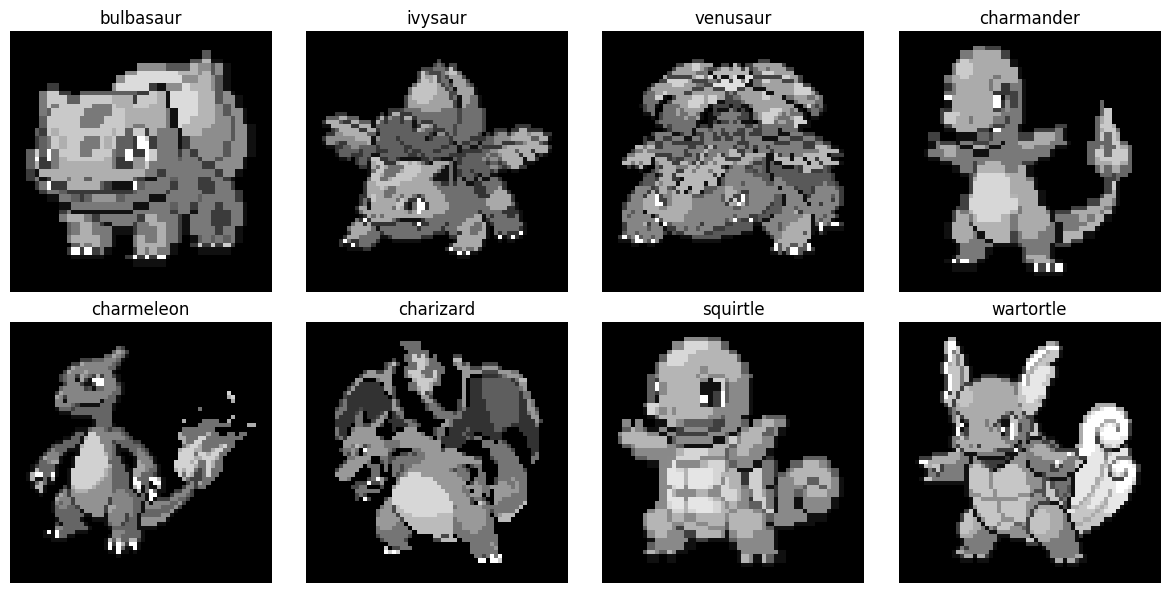

In [37]:
fig, axes = plt.subplots(
    2,
    4,
    figsize=(12, 6)
)

for i, ax in enumerate(axes.flat):

    image, mask, condition = train_dataset[i]

    row = train_dataset.df.iloc[i]

    ax.imshow(
        image.squeeze(0).numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(row["pokemon_name"])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [38]:
# Verificar quantidade de amostras
assert len(train_dataset) == 905
assert len(val_dataset) == 60
assert len(test_dataset) == 60

# Verificar dimensões das condições
assert train_dataset.conditions.shape == (905, 24)
assert val_dataset.conditions.shape == (60, 24)
assert test_dataset.conditions.shape == (60, 24)

# Verificar valores das condições
for dataset in [train_dataset, val_dataset, test_dataset]:

    assert np.isfinite(dataset.conditions).all()

    # Primeiras 18 posições: Multi-Hot
    assert np.isin(
        dataset.conditions[:, :18],
        [0.0, 1.0]
    ).all()

    # Últimas 6 posições: status normalizados
    assert (
        dataset.conditions[:, 18:] >= 0
    ).all()

    assert (
        dataset.conditions[:, 18:] <= 1
    ).all()

print("Todas as verificações foram aprovadas!")

Todas as verificações foram aprovadas!


# Arquitetura do Ultraball


In [39]:
import torch.nn as nn
import torch.nn.functional as F


In [40]:
def reparameterize(mu, logvar):

    std = torch.exp(0.5 * logvar)

    epsilon = torch.randn_like(std)

    z = mu + std * epsilon

    return z

In [41]:
class SpatialEncoder16(nn.Module):

    def __init__(
        self,
        condition_dim=24,
        latent_channels=16
    ):

        super().__init__()

        self.features = nn.Sequential(

            # 64x64 -> 32x32
            nn.Conv2d(
                1 + condition_dim,
                64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            # 32x32 -> 16x16
            nn.Conv2d(
                64,
                128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # Refinamento espacial 16x16
            nn.Conv2d(
                128,
                192,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(192),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                192,
                192,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(192),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                192,
                192,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(192),
            nn.LeakyReLU(0.2, inplace=True),

            # Preparar representação latente
            nn.Conv2d(
                192,
                128,
                kernel_size=1
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True)
        )

        # Projeções espaciais para os parâmetros da distribuição
        self.mu_head = nn.Conv2d(
            128,
            latent_channels,
            kernel_size=1
        )

        self.logvar_head = nn.Conv2d(
            128,
            latent_channels,
            kernel_size=1
        )

        # Inicialização pequena da média
        nn.init.xavier_uniform_(
            self.mu_head.weight,
            gain=0.1
        )

        nn.init.zeros_(
            self.mu_head.bias
        )

        # Inicializar logvar em zero:
        # distribuição inicial próxima de N(0, I)
        nn.init.zeros_(
            self.logvar_head.weight
        )

        nn.init.zeros_(
            self.logvar_head.bias
        )

    def forward(self, x, c):

        batch_size = x.size(0)

        height = x.size(2)
        width = x.size(3)

        # Expandir condições espacialmente
        c_map = c.unsqueeze(-1).unsqueeze(-1)

        c_map = c_map.expand(
            batch_size,
            c.size(1),
            height,
            width
        )

        # Concatenar imagem e condições
        x = torch.cat(
            [x, c_map],
            dim=1
        )

        # Extração espacial
        features = self.features(x)

        # Parâmetros da distribuição latente
        mu = self.mu_head(features)

        raw_logvar = self.logvar_head(features)

        # Estabilização suave
        LOGVAR_LIMIT = 6.0

        logvar = LOGVAR_LIMIT * torch.tanh(
            raw_logvar / LOGVAR_LIMIT
        )

        return mu, logvar

In [42]:
class SpatialDecoder16(nn.Module):

    def __init__(
        self,
        latent_channels=16,
        condition_dim=24
    ):

        super().__init__()

        input_channels = latent_channels + condition_dim

        self.initial = nn.Sequential(

            nn.Conv2d(
                input_channels,
                192,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(192),
            nn.ReLU(inplace=True)
        )

        # Refinamento em 16x16
        self.refine = nn.Sequential(

            nn.Conv2d(
                192,
                192,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(192),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                192,
                192,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(192),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                192,
                128,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )

        # 16x16 -> 32x32
        self.up32 = nn.Sequential(

            nn.Upsample(
                scale_factor=2,
                mode="nearest"
            ),

            nn.Conv2d(
                128,
                96,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(96),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                96,
                96,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(96),
            nn.ReLU(inplace=True)
        )

        # 32x32 -> 64x64
        self.up64 = nn.Sequential(

            nn.Upsample(
                scale_factor=2,
                mode="nearest"
            ),

            nn.Conv2d(
                96,
                64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                64,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        # Refinamento final e saída grayscale
        self.output = nn.Sequential(

            nn.Conv2d(
                32,
                1,
                kernel_size=3,
                padding=1
            ),

            nn.Sigmoid()
        )

    def forward(self, z, c):

        batch_size = z.size(0)

        height = z.size(2)
        width = z.size(3)

        # Expandir condições para 16x16
        c_map = c.unsqueeze(-1).unsqueeze(-1)

        c_map = c_map.expand(
            batch_size,
            c.size(1),
            height,
            width
        )

        # Concatenar latente e condições
        x = torch.cat(
            [z, c_map],
            dim=1
        )

        x = self.initial(x)

        x = self.refine(x)

        x = self.up32(x)

        x = self.up64(x)

        reconstruction = self.output(x)

        return reconstruction

In [43]:
class CVAESpatial16(nn.Module):

    def __init__(
        self,
        latent_channels=16,
        condition_dim=24
    ):

        super().__init__()

        self.latent_channels = latent_channels
        self.condition_dim = condition_dim

        self.encoder = SpatialEncoder16(
            condition_dim=condition_dim,
            latent_channels=latent_channels
        )

        self.decoder = SpatialDecoder16(
            latent_channels=latent_channels,
            condition_dim=condition_dim
        )

    def forward(self, x, c):

        mu, logvar = self.encoder(x, c)

        z = reparameterize(
            mu,
            logvar
        )

        reconstruction = self.decoder(
            z,
            c
        )

        return reconstruction, mu, logvar

    def reconstruct(self, x, c):

        # Reconstrução determinística
        mu, logvar = self.encoder(x, c)

        reconstruction = self.decoder(
            mu,
            c
        )

        return reconstruction

    def generate(self, c, z=None):

        batch_size = c.size(0)

        if z is None:

            z = torch.randn(
                batch_size,
                self.latent_channels,
                16,
                16,
                device=c.device,
                dtype=c.dtype
            )

        return self.decoder(
            z,
            c
        )

In [44]:
LATENT_CHANNELS = 16
LATENT_SIZE = 16

CONDITION_DIM = 24

LATENT_ELEMENTS = (
    LATENT_CHANNELS
    * LATENT_SIZE
    * LATENT_SIZE
)

REFERENCE_LATENT_DIM = 128

KL_NORMALIZATION = (
    LATENT_ELEMENTS
    / REFERENCE_LATENT_DIM
)

print("Canais latentes:", LATENT_CHANNELS)
print("Resolução latente:", LATENT_SIZE, "x", LATENT_SIZE)
print("Total de variáveis latentes:", LATENT_ELEMENTS)
print("Fator de normalização da KL:", KL_NORMALIZATION)

Canais latentes: 16
Resolução latente: 16 x 16
Total de variáveis latentes: 4096
Fator de normalização da KL: 32.0


In [45]:
def spatial_kl_divergence(mu, logvar):

    kl_per_sample = -0.5 * (
        1
        + logvar
        - mu.pow(2)
        - logvar.exp()
    ).sum(dim=(1, 2, 3))

    kl_raw = kl_per_sample.mean()

    kl_normalized = (
        kl_raw / KL_NORMALIZATION
    )

    return kl_normalized, kl_raw

In [46]:
LAMBDA_BG = 0.1


def cvae_spatial_loss(
    x,
    reconstruction,
    mask,
    mu,
    logvar,
    beta=1.0,
    lambda_bg=0.1
):

    pixel_error = torch.abs(
        x - reconstruction
    )

    # Foreground
    foreground_loss = (
        pixel_error * mask
    ).sum(dim=(1, 2, 3)).mean()

    # Background
    background_loss = (
        pixel_error * (1.0 - mask)
    ).sum(dim=(1, 2, 3)).mean()

    # KL espacial normalizada
    kl_loss, kl_raw = spatial_kl_divergence(
        mu,
        logvar
    )

    # Reconstrução ponderada
    reconstruction_loss = (
        foreground_loss
        + lambda_bg * background_loss
    )

    # Loss total
    total_loss = (
        reconstruction_loss
        + beta * kl_loss
    )

    return (
        total_loss,
        foreground_loss,
        background_loss,
        kl_loss,
        kl_raw
    )

In [47]:
model_spatial = CVAESpatial16(
    latent_channels=LATENT_CHANNELS,
    condition_dim=CONDITION_DIM
).to(DEVICE)

total_parameters = sum(
    p.numel()
    for p in model_spatial.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model_spatial.parameters()
    if p.requires_grad
)

print("CVAESpatial16 criado!")
print("Total de parâmetros:", f"{total_parameters:,}")
print("Parâmetros treináveis:", f"{trainable_parameters:,}")

CVAESpatial16 criado!
Total de parâmetros: 2,297,185
Parâmetros treináveis: 2,297,185


In [48]:
images, masks, conditions = next(
    iter(train_loader)
)

images = images.to(DEVICE)
masks = masks.to(DEVICE)
conditions = conditions.to(DEVICE)

model_spatial.eval()

if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

with torch.no_grad():

    # Verificar mapa intermediário do encoder
    c_map = conditions.unsqueeze(-1).unsqueeze(-1)

    c_map = c_map.expand(
        images.size(0),
        CONDITION_DIM,
        64,
        64
    )

    encoder_input = torch.cat(
        [images, c_map],
        dim=1
    )

    encoder_features = model_spatial.encoder.features(
        encoder_input
    )

    # Forward completo
    reconstruction, mu, logvar = model_spatial(
        images,
        conditions
    )

print("Entrada do encoder:", encoder_input.shape)
print("Features do encoder:", encoder_features.shape)

print("\nDistribuição latente:")
print("Mu:", mu.shape)
print("Logvar:", logvar.shape)

print("\nReconstrução:")
print(reconstruction.shape)

if DEVICE.type == "cuda":

    peak_memory = (
        torch.cuda.max_memory_allocated(DEVICE)
        / 1024**3
    )

    print(f"\nPico de memória GPU: {peak_memory:.2f} GB")

Entrada do encoder: torch.Size([32, 25, 64, 64])
Features do encoder: torch.Size([32, 128, 16, 16])

Distribuição latente:
Mu: torch.Size([32, 16, 16, 16])
Logvar: torch.Size([32, 16, 16, 16])

Reconstrução:
torch.Size([32, 1, 64, 64])

Pico de memória GPU: 0.12 GB


In [49]:
assert encoder_features.shape == (32, 128, 16, 16)

assert mu.shape == (32, 16, 16, 16)
assert logvar.shape == (32, 16, 16, 16)

assert reconstruction.shape == (32, 1, 64, 64)

assert torch.isfinite(mu).all()
assert torch.isfinite(logvar).all()
assert torch.isfinite(reconstruction).all()

print("Dimensões validadas!")

Dimensões validadas!


In [50]:
with torch.no_grad():

    (
        total_loss,
        fg_loss,
        bg_loss,
        kl_loss,
        kl_raw
    ) = cvae_spatial_loss(
        images,
        reconstruction,
        masks,
        mu,
        logvar,
        beta=1.0,
        lambda_bg=LAMBDA_BG
    )

print("Foreground:", fg_loss.item())
print("Background:", bg_loss.item())

print("\nKL bruta:", kl_raw.item())
print("KL normalizada:", kl_loss.item())

print("\nKL ponderada:", kl_loss.item())

print("Loss total:", total_loss.item())

Foreground: 332.7869873046875
Background: 1376.806640625

KL bruta: 0.01785816252231598
KL normalizada: 0.0005580675788223743

KL ponderada: 0.0005580675788223743
Loss total: 470.46820068359375


In [51]:
assert all(
    torch.isfinite(value)
    for value in [
        total_loss,
        fg_loss,
        bg_loss,
        kl_loss,
        kl_raw
    ]
)

print("Função de perda validada!")

Função de perda validada!


In [52]:
def show_reconstructions_model(
    model_to_show,
    dataset,
    num_samples=8
):

    model_to_show.eval()

    num_samples = min(
        num_samples,
        len(dataset)
    )

    fig, axes = plt.subplots(
        3,
        num_samples,
        figsize=(2.5 * num_samples, 8)
    )

    with torch.no_grad():

        for i in range(num_samples):

            image, mask, condition = dataset[i]

            image_input = image.unsqueeze(0).to(DEVICE)
            condition_input = condition.unsqueeze(0).to(DEVICE)

            reconstruction = model_to_show.reconstruct(
                image_input,
                condition_input
            )

            original = image.squeeze(0).numpy()
            mask_np = mask.squeeze(0).numpy()

            reconstructed = (
                reconstruction.squeeze(0)
                .squeeze(0)
                .cpu()
                .numpy()
            )

            row = dataset.df.iloc[i]

            axes[0, i].imshow(
                original,
                cmap="gray",
                vmin=0,
                vmax=1
            )

            axes[0, i].set_title(
                f"{row['pokemon_name']}\nOriginal"
            )

            axes[1, i].imshow(
                mask_np,
                cmap="gray",
                vmin=0,
                vmax=1
            )

            axes[1, i].set_title("Máscara")

            axes[2, i].imshow(
                reconstructed,
                cmap="gray",
                vmin=0,
                vmax=1
            )

            axes[2, i].set_title("Reconstrução direta")

            for ax in axes[:, i]:
                ax.axis("off")

    plt.tight_layout()
    plt.show()

# Treinamento do Ultraball: peso e warm-up da KL

A arquitetura permanece a mesma. Na configuracao original, beta vai ate 1 em 40 epocas.
O teste selecionado usa beta final 2 e warm-up de 80 epocas. Como a KL e dividida por 32,
o coeficiente final sobre a KL bruta passa de 1/32 para 2/32. A subida inicial permanece
igual: beta=0,025 na epoca 1 e beta=1 na epoca 40; depois continua ate beta=2 na epoca 80.

Hipotese: maior regularizacao pode reduzir a diferenca entre os latentes codificados e o
prior usado para gerar. Pode tambem piorar a reconstrucao ou fazer o decoder ignorar z.
Ainda nao e uma melhora comprovada. Compare geracoes pelo prior com condicoes e sementes
fixas, detalhes reconstruidos, diversidade e KL por canal. Nao escolha beta usando o teste.

Na celula de configuracao, `SPATIAL_EXPERIMENT = "original"` recupera o treino anterior;
`"kl_reforcada"` seleciona o ajuste. O modelo e reinicializado do zero e cada configuracao
usa nomes distintos de checkpoint e historico. Para um estudo em que se altere apenas um
fator, use primeiro beta=2 com warm-up=40; depois compare warm-up=40 e 80 com beta=2.
A configuracao proposta altera os dois fatores e deve ser interpretada dessa forma.

A validacao e o scheduler usam beta final fixo; o historico separa KL bruta, normalizada e
ponderada. As saidas posteriores a esta secao foram limpas porque pertenciam ao treino
anterior. Execute desde a configuracao do Ultraball ate os testes de condicoes para obter
novos resultados. Os pesos antigos nao sao modificados ao executar a configuracao reforcada.


In [53]:
def train_one_epoch_spatial(
    model,
    loader,
    optimizer,
    beta,
    lambda_bg,
    beta_reference=1.0
):

    model.train()

    total_fg = 0.0
    total_bg = 0.0

    total_kl = 0.0
    total_kl_raw = 0.0

    total_objective = 0.0

    max_abs_logvar = 0.0
    num_samples = 0

    for images, masks, conditions in loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)
        conditions = conditions.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        reconstruction, mu, logvar = model(
            images,
            conditions
        )

        if not torch.isfinite(logvar).all():
            raise FloatingPointError(
                "Logvar contém valores não finitos."
            )

        max_abs_logvar = max(
            max_abs_logvar,
            logvar.abs().max().item()
        )

        (
            loss,
            fg_loss,
            bg_loss,
            kl_loss,
            kl_raw
        ) = cvae_spatial_loss(
            images,
            reconstruction,
            masks,
            mu,
            logvar,
            beta=beta,
            lambda_bg=lambda_bg
        )

        if not torch.isfinite(loss):
            raise FloatingPointError(
                "Loss não finita durante o treinamento."
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP
        )

        optimizer.step()

        batch_size = images.size(0)

        total_fg += fg_loss.item() * batch_size
        total_bg += bg_loss.item() * batch_size

        total_kl += kl_loss.item() * batch_size
        total_kl_raw += kl_raw.item() * batch_size

        total_objective += loss.item() * batch_size

        num_samples += batch_size

    avg_fg = total_fg / num_samples
    avg_bg = total_bg / num_samples

    avg_kl = total_kl / num_samples
    avg_kl_raw = total_kl_raw / num_samples

    avg_objective = total_objective / num_samples

    # Objetivo com o beta final fixo como referencia.
    avg_total = (
        avg_fg
        + lambda_bg * avg_bg
        + beta_reference * avg_kl
    )

    return {
        "total": avg_total,
        "objective": avg_objective,

        "foreground": avg_fg,
        "background": avg_bg,

        "kl": avg_kl,
        "kl_raw": avg_kl_raw,
        "kl_weighted": beta * avg_kl,
        "kl_reference": beta_reference * avg_kl,

        "max_abs_logvar": max_abs_logvar
    }

In [54]:
def evaluate_spatial(
    model,
    loader,
    lambda_bg=0.1,
    beta=1.0
):

    model.eval()

    total_fg = 0.0
    total_bg = 0.0

    total_kl = 0.0
    total_kl_raw = 0.0

    num_samples = 0

    with torch.no_grad():

        for images, masks, conditions in loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)
            conditions = conditions.to(DEVICE)

            # Encoder
            mu, logvar = model.encoder(
                images,
                conditions
            )

            # Decoder determinístico
            reconstruction = model.decoder(
                mu,
                conditions
            )

            (
                loss,
                fg_loss,
                bg_loss,
                kl_loss,
                kl_raw
            ) = cvae_spatial_loss(
                images,
                reconstruction,
                masks,
                mu,
                logvar,
                beta=beta,
                lambda_bg=lambda_bg
            )

            batch_size = images.size(0)

            total_fg += fg_loss.item() * batch_size
            total_bg += bg_loss.item() * batch_size

            total_kl += kl_loss.item() * batch_size
            total_kl_raw += kl_raw.item() * batch_size

            num_samples += batch_size

    avg_fg = total_fg / num_samples
    avg_bg = total_bg / num_samples

    avg_kl = total_kl / num_samples
    avg_kl_raw = total_kl_raw / num_samples

    avg_total = (
        avg_fg
        + lambda_bg * avg_bg
        + beta * avg_kl
    )

    return {
        "total": avg_total,

        "foreground": avg_fg,
        "background": avg_bg,

        "kl": avg_kl,
        "kl_raw": avg_kl_raw,
        "kl_weighted": beta * avg_kl
    }

In [55]:
# Semente
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Reinicializar o modelo
model_spatial = CVAESpatial16(
    latent_channels=LATENT_CHANNELS,
    condition_dim=CONDITION_DIM
).to(DEVICE)

# DataLoader reproduzível
generator = torch.Generator()
generator.manual_seed(SEED)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=generator
)

# Hiperparâmetros
EPOCHS = 150

LEARNING_RATE = 1e-3

# Trocar para "original" reproduz beta=1 / warm-up=40.
SPATIAL_EXPERIMENT = "kl_reforcada"
SPATIAL_KL_CONFIGS = {
    "original": {"beta_max": 1.0, "warmup_epochs": 40},
    "kl_reforcada": {"beta_max": 2.0, "warmup_epochs": 80}
}
kl_config = SPATIAL_KL_CONFIGS[SPATIAL_EXPERIMENT]
BETA_MAX = kl_config["beta_max"]
BETA_WARMUP_EPOCHS = kl_config["warmup_epochs"]

def spatial_beta(epoch, beta_max, warmup_epochs):
    # epoch comeca em zero. O teto e beta_max, mesmo quando maior que 1.
    if epoch < 0 or beta_max < 0 or warmup_epochs <= 0:
        raise ValueError("Epoca e beta devem ser nao negativos; warm-up deve ser positivo.")
    return beta_max * min(1.0, (epoch + 1) / warmup_epochs)

SPATIAL_RUN_NAME = "cvae_spatial_16x16x16"
if SPATIAL_EXPERIMENT != "original":
    SPATIAL_RUN_NAME += f"_kl_beta{BETA_MAX:g}_warmup{BETA_WARMUP_EPOCHS}"

LAMBDA_BG = 0.1

PATIENCE = 20
SCHEDULER_PATIENCE = 7

MIN_DELTA = 1e-4
MIN_LR = 1e-6
GRAD_CLIP = 5.0

optimizer_spatial = torch.optim.Adam(
    model_spatial.parameters(),
    lr=LEARNING_RATE
)

scheduler_spatial = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_spatial,
    mode="min",
    factor=0.5,
    patience=SCHEDULER_PATIENCE,
    min_lr=MIN_LR
)

print("Treinamento espacial configurado!")
print("Latent shape:", (16, 16, 16))
print("Variáveis latentes:", LATENT_ELEMENTS)
print("KL normalization:", KL_NORMALIZATION)
print("Lambda background:", LAMBDA_BG)

print("Experimento:", SPATIAL_EXPERIMENT)
print("Beta final:", BETA_MAX, "| Warm-up:", BETA_WARMUP_EPOCHS)
print("Coeficiente final da KL bruta:", BETA_MAX / KL_NORMALIZATION)
print("Beta nas epocas 1, 40, 80:", [spatial_beta(e - 1, BETA_MAX, BETA_WARMUP_EPOCHS) for e in [1, 40, 80]])


Treinamento espacial configurado!
Latent shape: (16, 16, 16)
Variáveis latentes: 4096
KL normalization: 32.0
Lambda background: 0.1
Experimento: kl_reforcada
Beta final: 2.0 | Warm-up: 80
Coeficiente final da KL bruta: 0.0625
Beta nas epocas 1, 40, 80: [0.025, 1.0, 2.0]


In [56]:
CHECKPOINT_SPATIAL_PATH = os.path.join(
    BASE_DIR,
    f"{SPATIAL_RUN_NAME}_best.pt"
)

HISTORY_SPATIAL_PATH = os.path.join(
    BASE_DIR,
    f"{SPATIAL_RUN_NAME}_history.csv"
)

history_spatial = []

best_val_loss = float("inf")
best_epoch = 0

epochs_without_improvement = 0

for epoch in range(EPOCHS):

    # Beta warm-up linear
    beta = spatial_beta(epoch, BETA_MAX, BETA_WARMUP_EPOCHS)

    # Treinamento
    train_metrics = train_one_epoch_spatial(
        model_spatial,
        train_loader,
        optimizer_spatial,
        beta,
        LAMBDA_BG,
        beta_reference=BETA_MAX
    )

    # Objetivo com o beta final fixo como referencia.
    val_metrics = evaluate_spatial(
        model_spatial,
        val_loader,
        lambda_bg=LAMBDA_BG,
        beta=BETA_MAX
    )

    # Scheduler
    scheduler_spatial.step(
        val_metrics["total"]
    )

    current_lr = optimizer_spatial.param_groups[0]["lr"]

    # Histórico
    epoch_data = {
        "epoch": epoch + 1,
        "beta": beta,
        "lr": current_lr,

        "train_total": train_metrics["total"],
        "train_objective": train_metrics["objective"],

        "train_foreground": train_metrics["foreground"],
        "train_background": train_metrics["background"],

        "train_kl": train_metrics["kl"],
        "train_kl_raw": train_metrics["kl_raw"],
        "train_kl_weighted": train_metrics["kl_weighted"],
        "train_kl_reference": train_metrics["kl_reference"],

        "train_max_abs_logvar": train_metrics["max_abs_logvar"],

        "val_total": val_metrics["total"],

        "val_foreground": val_metrics["foreground"],
        "val_background": val_metrics["background"],

        "val_kl": val_metrics["kl"],
        "val_kl_raw": val_metrics["kl_raw"],
        "val_kl_weighted": val_metrics["kl_weighted"]
    }

    history_spatial.append(epoch_data)

    # Salvar melhor checkpoint
    if val_metrics["total"] < best_val_loss - MIN_DELTA:

        best_val_loss = float(val_metrics["total"])
        best_epoch = epoch + 1

        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": best_epoch,

                "model_state_dict": model_spatial.state_dict(),
                "optimizer_state_dict": optimizer_spatial.state_dict(),

                "best_val_loss": float(best_val_loss),

                "latent_channels": LATENT_CHANNELS,
                "latent_size": LATENT_SIZE,
                "latent_elements": LATENT_ELEMENTS,

                "condition_dim": CONDITION_DIM,

                "kl_normalization": float(KL_NORMALIZATION),
                "reference_latent_dim": REFERENCE_LATENT_DIM,

                "lambda_bg": float(LAMBDA_BG),

                "experiment": SPATIAL_EXPERIMENT,
                "validation_beta": float(BETA_MAX),
                "beta_at_epoch": float(beta),
                "beta_max": float(BETA_MAX),
                "beta_warmup_epochs": BETA_WARMUP_EPOCHS,

                "logvar_limit": 6.0,

                "seed": SEED
            },
            CHECKPOINT_SPATIAL_PATH
        )

        status = "Melhor modelo salvo!"

    else:

        status = ""

        if epoch + 1 >= BETA_WARMUP_EPOCHS:
            epochs_without_improvement += 1

    # Salvar histórico
    pd.DataFrame(history_spatial).to_csv(
        HISTORY_SPATIAL_PATH,
        index=False
    )

    print(
        f"Epoch [{epoch + 1:03d}/{EPOCHS}] "
        f"Beta: {beta:.3f} | "
        f"LR: {current_lr:.6f} | "

        f"Train FG: {train_metrics['foreground']:.2f} | "
        f"Train BG: {train_metrics['background']:.2f} | "

        f"KL norm: {train_metrics['kl']:.3f} | "
        f"Beta*KL: {train_metrics['kl_weighted']:.3f} | "
        f"KL raw: {train_metrics['kl_raw']:.2f} | "

        f"Val FG: {val_metrics['foreground']:.2f} | "
        f"Val BG: {val_metrics['background']:.2f} | "

        f"Val KL: {val_metrics['kl']:.3f} | "
        f"{status}"
    )

    # Early stopping
    if (
        epoch + 1 >= BETA_WARMUP_EPOCHS
        and epochs_without_improvement >= PATIENCE
    ):

        print(
            f"\nEarly stopping na época {epoch + 1}."
        )

        break


print("\nTreinamento finalizado!")
print("Melhor época:", best_epoch)
print("Melhor validação:", best_val_loss)
print("Checkpoint:", CHECKPOINT_SPATIAL_PATH)

Epoch [001/150] Beta: 0.025 | LR: 0.001000 | Train FG: 301.49 | Train BG: 559.13 | KL norm: 9.411 | Beta*KL: 0.235 | KL raw: 301.14 | Val FG: 538.27 | Val BG: 313.68 | Val KL: 44.087 | Melhor modelo salvo!
Epoch [002/150] Beta: 0.050 | LR: 0.001000 | Train FG: 239.06 | Train BG: 125.46 | KL norm: 56.492 | Beta*KL: 2.825 | KL raw: 1807.73 | Val FG: 318.61 | Val BG: 112.78 | Val KL: 104.794 | Melhor modelo salvo!
Epoch [003/150] Beta: 0.075 | LR: 0.001000 | Train FG: 211.86 | Train BG: 63.76 | KL norm: 57.941 | Beta*KL: 4.346 | KL raw: 1854.10 | Val FG: 198.75 | Val BG: 41.98 | Val KL: 56.075 | Melhor modelo salvo!
Epoch [004/150] Beta: 0.100 | LR: 0.001000 | Train FG: 197.12 | Train BG: 45.08 | KL norm: 56.631 | Beta*KL: 5.663 | KL raw: 1812.20 | Val FG: 181.72 | Val BG: 41.17 | Val KL: 51.557 | Melhor modelo salvo!
Epoch [005/150] Beta: 0.125 | LR: 0.001000 | Train FG: 190.80 | Train BG: 37.66 | KL norm: 52.241 | Beta*KL: 6.530 | KL raw: 1671.73 | Val FG: 185.68 | Val BG: 27.80 | Val K

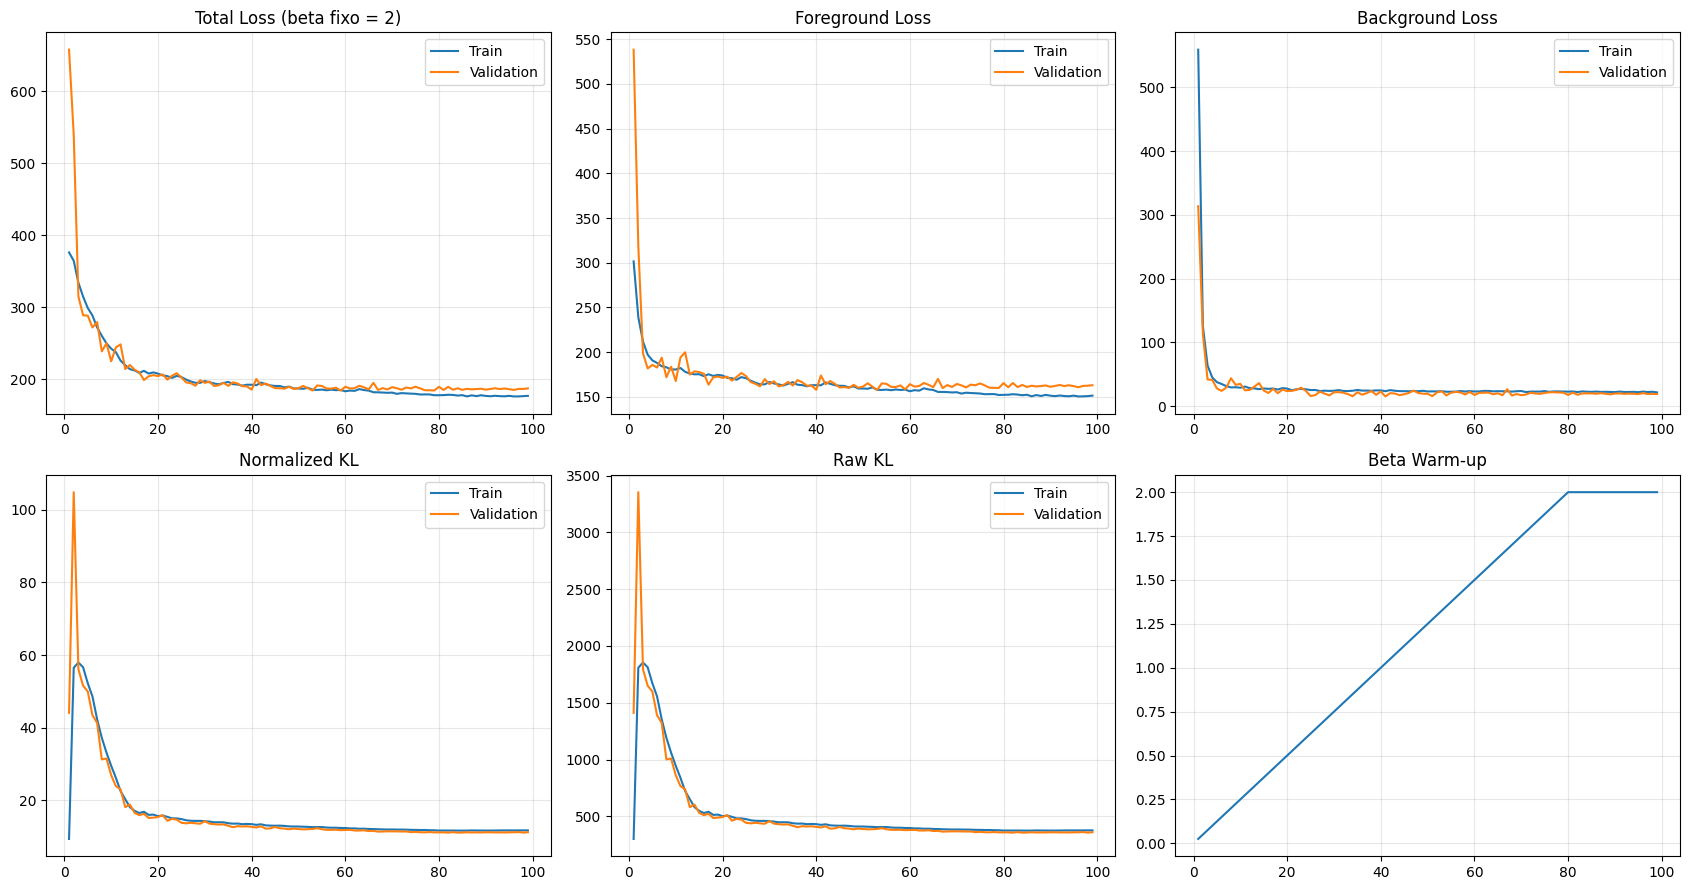

In [57]:
history_spatial_df = pd.DataFrame(history_spatial)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(17, 9)
)

# Total loss
axes[0, 0].plot(
    history_spatial_df["epoch"],
    history_spatial_df["train_total"],
    label="Train"
)

axes[0, 0].plot(
    history_spatial_df["epoch"],
    history_spatial_df["val_total"],
    label="Validation"
)

axes[0, 0].set_title(f"Total Loss (beta fixo = {BETA_MAX:g})")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Foreground
axes[0, 1].plot(
    history_spatial_df["epoch"],
    history_spatial_df["train_foreground"],
    label="Train"
)

axes[0, 1].plot(
    history_spatial_df["epoch"],
    history_spatial_df["val_foreground"],
    label="Validation"
)

axes[0, 1].set_title("Foreground Loss")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Background
axes[0, 2].plot(
    history_spatial_df["epoch"],
    history_spatial_df["train_background"],
    label="Train"
)

axes[0, 2].plot(
    history_spatial_df["epoch"],
    history_spatial_df["val_background"],
    label="Validation"
)

axes[0, 2].set_title("Background Loss")
axes[0, 2].legend()
axes[0, 2].grid(alpha=0.3)

# KL normalizada
axes[1, 0].plot(
    history_spatial_df["epoch"],
    history_spatial_df["train_kl"],
    label="Train"
)

axes[1, 0].plot(
    history_spatial_df["epoch"],
    history_spatial_df["val_kl"],
    label="Validation"
)

axes[1, 0].set_title("Normalized KL")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# KL bruta
axes[1, 1].plot(
    history_spatial_df["epoch"],
    history_spatial_df["train_kl_raw"],
    label="Train"
)

axes[1, 1].plot(
    history_spatial_df["epoch"],
    history_spatial_df["val_kl_raw"],
    label="Validation"
)

axes[1, 1].set_title("Raw KL")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

# Beta
axes[1, 2].plot(
    history_spatial_df["epoch"],
    history_spatial_df["beta"]
)

axes[1, 2].set_title("Beta Warm-up")
axes[1, 2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [58]:
print(
    "Maior |logvar|:",
    history_spatial_df["train_max_abs_logvar"].max()
)

print(
    "Maior KL bruta:",
    history_spatial_df["train_kl_raw"].max()
)

print(
    "Maior KL normalizada:",
    history_spatial_df["train_kl"].max()
)

Maior |logvar|: 5.925843238830566
Maior KL bruta: 1854.1014612018732
Maior KL normalizada: 57.94067066255854


In [59]:
checkpoint_spatial = torch.load(
    CHECKPOINT_SPATIAL_PATH,
    map_location=DEVICE,
    weights_only=True
)

model_spatial.load_state_dict(
    checkpoint_spatial["model_state_dict"]
)

model_spatial.eval()

print("Melhor modelo carregado!")
print("Época:", checkpoint_spatial["epoch"])
print("Validação:", checkpoint_spatial["best_val_loss"])

print(
    "Latente:",
    checkpoint_spatial["latent_channels"],
    "x",
    checkpoint_spatial["latent_size"],
    "x",
    checkpoint_spatial["latent_size"]
)

print(
    "Total de variáveis:",
    checkpoint_spatial["latent_elements"]
)

print("Experimento:", checkpoint_spatial.get("experiment", "original"))
print("Beta final:", checkpoint_spatial["beta_max"])
print("Beta na epoca salva:", checkpoint_spatial.get("beta_at_epoch", "nao registrado"))


Melhor modelo carregado!
Época: 59
Validação: 184.25182824452716
Latente: 16 x 16 x 16
Total de variáveis: 4096
Experimento: kl_reforcada
Beta final: 2.0
Beta na epoca salva: 1.475


In [60]:
test_spatial_metrics = evaluate_spatial(
    model_spatial,
    test_loader,
    lambda_bg=LAMBDA_BG,
    beta=checkpoint_spatial["beta_max"]
)

print("Resultados no teste:")
print(
    f"Foreground: {test_spatial_metrics['foreground']:.4f}"
)

print(
    f"Background: {test_spatial_metrics['background']:.4f}"
)

print(
    f"KL normalizada: {test_spatial_metrics['kl']:.4f}"
)

print(
    f"KL bruta: {test_spatial_metrics['kl_raw']:.4f}"
)

Resultados no teste:
Foreground: 155.1196
Background: 21.4839
KL normalizada: 11.8215
KL bruta: 378.2878


In [61]:
silhouette_spatial = evaluate_silhouette_fixed(
    model_spatial,
    test_loader,
    threshold=0.20
)

print(
    f"IoU: {silhouette_spatial['IoU']:.4f}"
)

print(
    f"Dice: {silhouette_spatial['Dice']:.4f}"
)

IoU: 0.8316
Dice: 0.9051


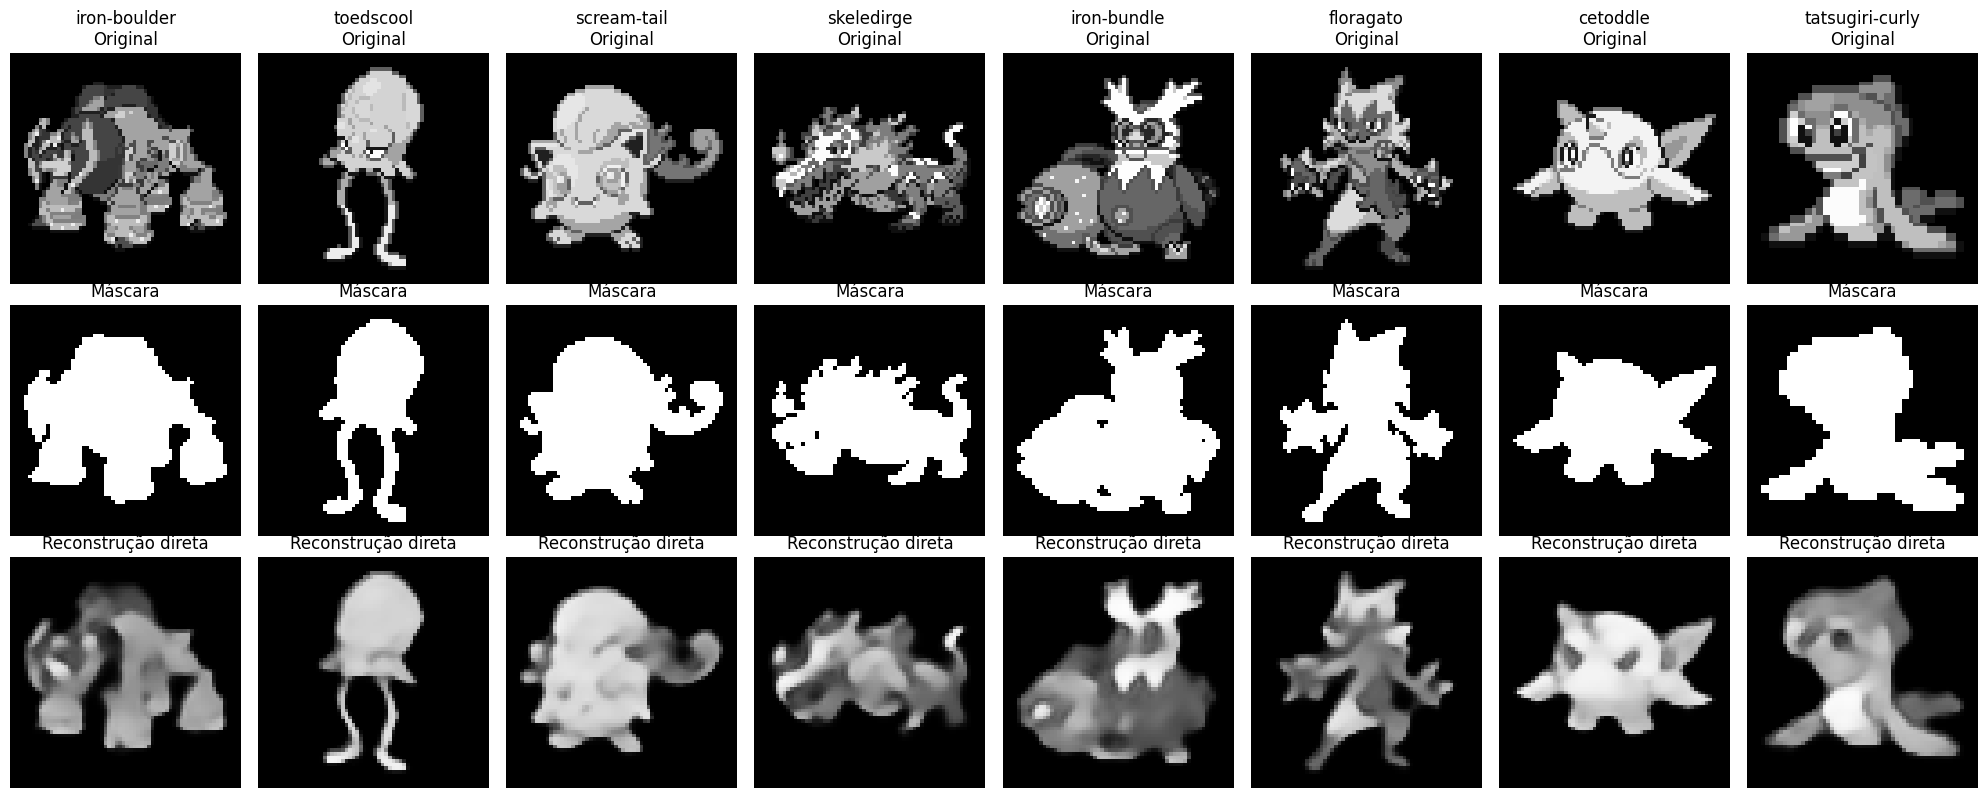

In [62]:
show_reconstructions_model(
    model_spatial,
    test_dataset,
    num_samples=8
)

In [63]:
def inspect_spatial_latent(model, loader):

    model.eval()

    all_mu = []
    all_logvar = []

    with torch.no_grad():

        for images, masks, conditions in loader:

            images = images.to(DEVICE)
            conditions = conditions.to(DEVICE)

            mu, logvar = model.encoder(
                images,
                conditions
            )

            all_mu.append(mu.cpu())
            all_logvar.append(logvar.cpu())

    mu = torch.cat(all_mu, dim=0)
    logvar = torch.cat(all_logvar, dim=0)

    std = torch.exp(0.5 * logvar)

    # KL por posição espacial e canal
    kl_map = -0.5 * (
        1 + logvar
        - mu.pow(2)
        - logvar.exp()
    )

    # Média por canal, batch e posições espaciais
    kl_per_channel = kl_map.mean(
        dim=(0, 2, 3)
    )

    print("Formato do mu:", mu.shape)

    print("\nDistribuição latente:")
    print("Mu mean:", mu.mean().item())
    print("Mu std:", mu.std().item())

    print("\nDesvio padrão:")
    print("Std mean:", std.mean().item())
    print("Std min:", std.min().item())
    print("Std max:", std.max().item())

    print("\nKL média por canal:")

    for i, value in enumerate(kl_per_channel):

        print(
            f"Canal {i:02d}: {value.item():.6f}"
        )

    return mu, logvar, kl_per_channel

In [64]:
latent_spatial_stats = inspect_spatial_latent(
    model_spatial,
    val_loader
)

Formato do mu: torch.Size([60, 16, 16, 16])

Distribuição latente:
Mu mean: 0.0019296075915917754
Mu std: 0.21991996467113495

Desvio padrão:
Std mean: 0.9581359624862671
Std min: 0.06310268491506577
Std max: 1.0286864042282104

KL média por canal:
Canal 00: 0.000067
Canal 01: 0.000070
Canal 02: 0.000039
Canal 03: 0.000130
Canal 04: 0.000047
Canal 05: 0.000082
Canal 06: 0.000063
Canal 07: 0.000035
Canal 08: 0.000137
Canal 09: 0.000064
Canal 10: 1.477354
Canal 11: 0.000061
Canal 12: 0.000070
Canal 13: 0.000051
Canal 14: 0.000181
Canal 15: 0.000065


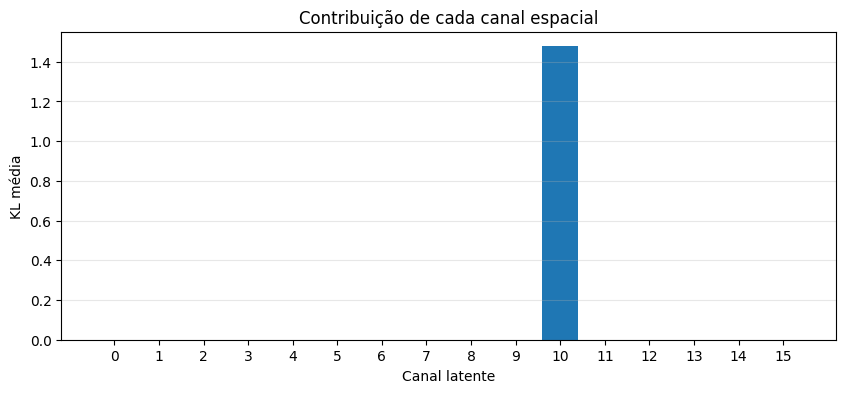

In [65]:
_, _, kl_per_channel = latent_spatial_stats

plt.figure(figsize=(10, 4))

plt.bar(
    range(LATENT_CHANNELS),
    kl_per_channel.numpy()
)

plt.xlabel("Canal latente")
plt.ylabel("KL média")
plt.title("Contribuição de cada canal espacial")

plt.xticks(range(LATENT_CHANNELS))
plt.grid(axis="y", alpha=0.3)

plt.show()

Teste das condições

In [66]:
# Usar o mesmo checkpoint do experimento recem-treinado.
SPATIAL_CHECKPOINT_PATH = CHECKPOINT_SPATIAL_PATH

checkpoint_cond = torch.load(
    SPATIAL_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

model_cond = CVAESpatial16(
    latent_channels=checkpoint_cond["latent_channels"],
    condition_dim=checkpoint_cond["condition_dim"]
).to(DEVICE)

model_cond.load_state_dict(
    checkpoint_cond["model_state_dict"]
)

model_cond.eval()

print("Checkpoint carregado!")
print("Época:", checkpoint_cond["epoch"])
print("Latente:", checkpoint_cond["latent_channels"], "x",
      checkpoint_cond["latent_size"], "x",
      checkpoint_cond["latent_size"])

Checkpoint carregado!
Época: 59
Latente: 16 x 16 x 16


In [67]:
STAT_COLUMNS = [
    "hp_norm",
    "attack_norm",
    "defense_norm",
    "special_attack_norm",
    "special_defense_norm",
    "speed_norm"
]

STAT_LABELS = {
    "hp_norm": "HP",
    "attack_norm": "Attack",
    "defense_norm": "Defense",
    "special_attack_norm": "Special Attack",
    "special_defense_norm": "Special Defense",
    "speed_norm": "Speed"
}

missing_columns = [
    col for col in STAT_COLUMNS
    if col not in train_df.columns
]

assert not missing_columns, (
    f"Colunas ausentes: {missing_columns}"
)

# Quantis calculados somente no treino
stat_quantiles = train_df[STAT_COLUMNS].quantile(
    [0.10, 0.50, 0.90]
)

display(stat_quantiles)

,hp_norm,attack_norm,defense_norm,special_attack_norm,special_defense_norm,speed_norm
0.1,0.156863,0.156863,0.156863,0.137255,0.156863,0.117647
0.5,0.254902,0.294118,0.266667,0.254902,0.254902,0.254902
0.9,0.392157,0.470588,0.431373,0.431373,0.411765,0.406275


In [68]:
FIXED_TYPES = ["grass", "poison"]

# Verificar os tipos
assert all(
    pokemon_type in POKEMON_TYPES
    for pokemon_type in FIXED_TYPES
)

# Vetor base com 24 dimensões
base_condition = np.zeros(
    CONDITION_DIM,
    dtype=np.float32
)

# Ativar os tipos
for pokemon_type in FIXED_TYPES:

    type_index = POKEMON_TYPES.index(
        pokemon_type
    )

    base_condition[type_index] = 1.0

# Valores medianos dos status
median_stats = stat_quantiles.loc[0.50, STAT_COLUMNS].values.astype(
    np.float32
)

base_condition[NUM_TYPES:] = median_stats

print("Tipos fixos:", FIXED_TYPES)
print("\nStatus medianos:")

for col, value in zip(STAT_COLUMNS, median_stats):
    print(f"{STAT_LABELS[col]}: {value:.4f}")

print("\nDimensão da condição:", base_condition.shape)

Tipos fixos: ['grass', 'poison']

Status medianos:
HP: 0.2549
Attack: 0.2941
Defense: 0.2667
Special Attack: 0.2549
Special Defense: 0.2549
Speed: 0.2549

Dimensão da condição: (24,)


In [69]:
variants = []

# Condição base
variants.append({
    "label": "Baseline\nMedian stats",
    "condition": base_condition.copy(),
    "stat": "Baseline",
    "level": "Median"
})

for i, col in enumerate(STAT_COLUMNS):

    # Condição com status baixo
    low_condition = base_condition.copy()

    low_condition[NUM_TYPES + i] = (
        stat_quantiles.loc[0.10, col]
    )

    variants.append({
        "label": f"{STAT_LABELS[col]}\nLow (Q10)",
        "condition": low_condition,
        "stat": STAT_LABELS[col],
        "level": "Low"
    })

    # Condição com status alto
    high_condition = base_condition.copy()

    high_condition[NUM_TYPES + i] = (
        stat_quantiles.loc[0.90, col]
    )

    variants.append({
        "label": f"{STAT_LABELS[col]}\nHigh (Q90)",
        "condition": high_condition,
        "stat": STAT_LABELS[col],
        "level": "High"
    })


conditions_np = np.stack([
    item["condition"]
    for item in variants
])

conditions_test = torch.tensor(
    conditions_np,
    dtype=torch.float32,
    device=DEVICE
)

print("Quantidade de condições:", len(variants))
print("Shape:", conditions_test.shape)

assert conditions_test.shape == (13, 24)

Quantidade de condições: 13
Shape: torch.Size([13, 24])


In [70]:
# Garantir reprodutibilidade
GENERATION_SEED = 2026

torch.manual_seed(GENERATION_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GENERATION_SEED)

# Um único vetor latente espacial
z_fixed = torch.randn(
    1,
    16,
    16,
    16,
    device=DEVICE
)

# Repetir o mesmo latente para todas as condições
z_repeated = z_fixed.expand(
    len(variants),
    -1,
    -1,
    -1
).contiguous()

model_cond.eval()

with torch.no_grad():

    generated = model_cond.generate(
        conditions_test,
        z=z_repeated
    )

print("Latente utilizado:", z_repeated.shape)
print("Condições:", conditions_test.shape)
print("Imagens geradas:", generated.shape)

Latente utilizado: torch.Size([13, 16, 16, 16])
Condições: torch.Size([13, 24])
Imagens geradas: torch.Size([13, 1, 64, 64])


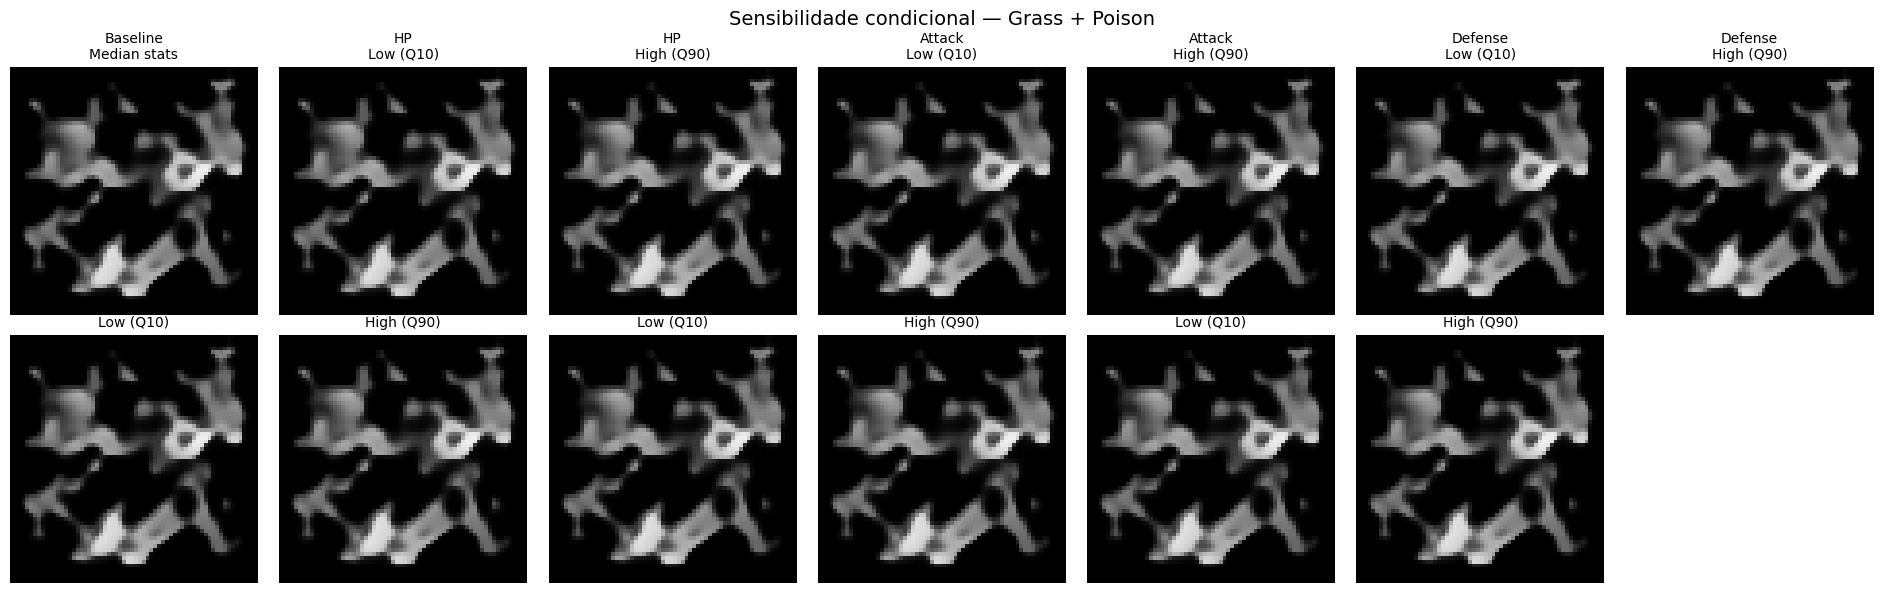

In [71]:
generated_np = (
    generated.squeeze(1)
    .cpu()
    .numpy()
)

fig, axes = plt.subplots(
    2,
    7,
    figsize=(19, 6)
)

axes = axes.flatten()

for i, item in enumerate(variants):

    axes[i].imshow(
        generated_np[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i].set_title(
        item["label"],
        fontsize=10
    )

    axes[i].axis("off")

# Ocultar o último espaço vazio
for i in range(len(variants), len(axes)):
    axes[i].axis("off")

fig.suptitle(
    "Sensibilidade condicional — Grass + Poison",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [72]:
baseline_image = generated_np[0]

sensitivity_results = []

for i, col in enumerate(STAT_COLUMNS):

    low_index = 1 + 2 * i
    high_index = 2 + 2 * i

    low_image = generated_np[low_index]
    high_image = generated_np[high_index]

    # Diferença entre status baixo e alto
    low_high_difference = np.abs(
        high_image - low_image
    )

    # Diferença de cada condição em relação ao baseline
    low_baseline_difference = np.abs(
        low_image - baseline_image
    )

    high_baseline_difference = np.abs(
        high_image - baseline_image
    )

    sensitivity_results.append({

        "Stat": STAT_LABELS[col],

        "Q10": stat_quantiles.loc[0.10, col],
        "Median": stat_quantiles.loc[0.50, col],
        "Q90": stat_quantiles.loc[0.90, col],

        "Low vs Baseline": low_baseline_difference.mean(),

        "High vs Baseline": high_baseline_difference.mean(),

        "Low vs High": low_high_difference.mean(),

        "Changed Pixels (%)": (
            low_high_difference > 0.02
        ).mean() * 100
    })


sensitivity_df = pd.DataFrame(
    sensitivity_results
)

display(
    sensitivity_df.style.format({
        "Q10": "{:.3f}",
        "Median": "{:.3f}",
        "Q90": "{:.3f}",
        "Low vs Baseline": "{:.4f}",
        "High vs Baseline": "{:.4f}",
        "Low vs High": "{:.4f}",
        "Changed Pixels (%)": "{:.2f}%"
    })
)

,Stat,Q10,Median,Q90,Low vs Baseline,High vs Baseline,Low vs High,Changed Pixels (%)
0,HP,0.157,0.255,0.392,0.0011,0.0015,0.0025,0.95%
1,Attack,0.157,0.294,0.471,0.0018,0.0022,0.0039,3.93%
2,Defense,0.157,0.267,0.431,0.0015,0.0023,0.0038,3.69%
3,Special Attack,0.137,0.255,0.431,0.0023,0.0036,0.0059,8.03%
4,Special Defense,0.157,0.255,0.412,0.0008,0.0013,0.0021,0.37%
5,Speed,0.118,0.255,0.406,0.0015,0.0016,0.0031,1.25%


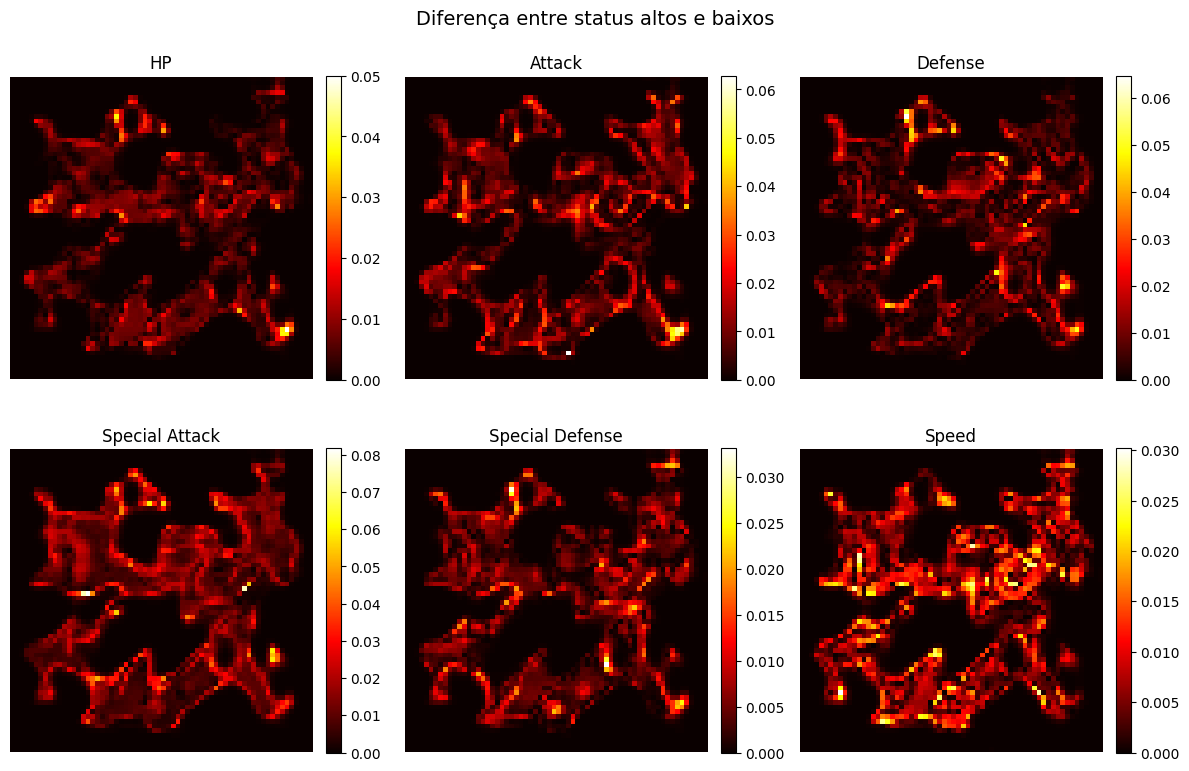

In [73]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(12, 8)
)

axes = axes.flatten()

for i, col in enumerate(STAT_COLUMNS):

    low_index = 1 + 2 * i
    high_index = 2 + 2 * i

    low_image = generated_np[low_index]
    high_image = generated_np[high_index]

    difference = np.abs(
        high_image - low_image
    )

    im = axes[i].imshow(
        difference,
        cmap="hot",
        vmin=0
    )

    axes[i].set_title(
        STAT_LABELS[col]
    )

    axes[i].axis("off")

    plt.colorbar(
        im,
        ax=axes[i],
        fraction=0.046,
        pad=0.04
    )

plt.suptitle(
    "Diferença entre status altos e baixos",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [74]:
N_LATENT_SEEDS = 16

multi_seed_results = {
    col: []
    for col in STAT_COLUMNS
}

model_cond.eval()

for seed in range(N_LATENT_SEEDS):

    torch.manual_seed(GENERATION_SEED + seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            GENERATION_SEED + seed
        )

    z = torch.randn(
        1,
        16,
        16,
        16,
        device=DEVICE
    )

    z_batch = z.expand(
        len(variants),
        -1,
        -1,
        -1
    ).contiguous()

    with torch.no_grad():

        outputs = model_cond.generate(
            conditions_test,
            z=z_batch
        )

    outputs = outputs.squeeze(1)

    for i, col in enumerate(STAT_COLUMNS):

        low_index = 1 + 2 * i
        high_index = 2 + 2 * i

        difference = torch.abs(
            outputs[high_index] - outputs[low_index]
        )

        sensitivity = difference.mean().item()

        multi_seed_results[col].append(
            sensitivity
        )


multi_seed_summary = []

for col in STAT_COLUMNS:

    values = multi_seed_results[col]

    multi_seed_summary.append({

        "Stat": STAT_LABELS[col],

        "Mean Sensitivity": np.mean(values),

        "Std Sensitivity": np.std(values),

        "Min Sensitivity": np.min(values),

        "Max Sensitivity": np.max(values)
    })


multi_seed_df = pd.DataFrame(
    multi_seed_summary
)

display(
    multi_seed_df.style.format({
        "Mean Sensitivity": "{:.5f}",
        "Std Sensitivity": "{:.5f}",
        "Min Sensitivity": "{:.5f}",
        "Max Sensitivity": "{:.5f}"
    })
)

,Stat,Mean Sensitivity,Std Sensitivity,Min Sensitivity,Max Sensitivity
0,HP,0.00242,0.00030,0.00186,0.00293
1,Attack,0.00334,0.00057,0.00245,0.00415
2,Defense,0.00361,0.00045,0.00251,0.00426
3,Special Attack,0.00559,0.00074,0.00415,0.00678
4,Special Defense,0.00186,0.00024,0.00152,0.00226
5,Speed,0.00269,0.00035,0.00213,0.00320


## Comparacao do Ultraball original com o ajuste de KL
Esta celula usa validacao e gera diretamente do prior. Nao usa imagens de teste para escolher
hiperparametros. Requer os dois checkpoints: execute a secao Ultraball com `original` e depois
com `kl_reforcada`, ou mantenha o checkpoint original que ja tiver treinado. A mesma matriz
de ruido e usada nos dois modelos, pois as arquiteturas sao identicas. O objetivo comum da
tabela e calculado com beta=1 para comparar os mesmos termos; ele nao substitui a avaliacao
visual da geracao. Modelos que ignorem z podem ter pouca diversidade mesmo com KL menor.


In [75]:
ORIGINAL_ULTRABALL_PATH = os.path.join(BASE_DIR, "cvae_spatial_16x16x16_best.pt")
ADJUSTED_ULTRABALL_PATH = os.path.join(BASE_DIR, "cvae_spatial_16x16x16_kl_beta2_warmup80_best.pt")

if not all(os.path.isfile(p) for p in [ORIGINAL_ULTRABALL_PATH, ADJUSTED_ULTRABALL_PATH]):
    print("Para comparar, treine as configuracoes original e kl_reforcada. Nenhum checkpoint sera substituido aqui.")
else:
    # Quatro combinacoes mais frequentes no treino; atributos medianos somente do treino.
    condition_columns_compare = TYPE_FEATURE_COLUMNS + NORMALIZED_STAT_COLUMNS
    type_rows = train_df[TYPE_FEATURE_COLUMNS].drop_duplicates().copy()
    type_counts = train_df.groupby(TYPE_FEATURE_COLUMNS).size()
    type_rows["count"] = [int(type_counts.loc[tuple(row)]) for row in type_rows.to_numpy()]
    type_rows = type_rows.sort_values("count", ascending=False).head(4)
    compare_vectors = np.concatenate([
        type_rows[TYPE_FEATURE_COLUMNS].to_numpy(dtype=np.float32),
        np.repeat(train_df[NORMALIZED_STAT_COLUMNS].median().to_numpy(dtype=np.float32)[None], len(type_rows), axis=0)
    ], axis=1)
    compare_c = torch.tensor(compare_vectors, device=DEVICE)
    generator_compare = torch.Generator(device=DEVICE).manual_seed(2026)
    samples_per_condition = 4
    compare_z = torch.randn(samples_per_condition, LATENT_CHANNELS, LATENT_SIZE, LATENT_SIZE,
                            generator=generator_compare, device=DEVICE)
    compare_z = compare_z.repeat(len(compare_c), 1, 1, 1)
    compare_c = compare_c.repeat_interleave(samples_per_condition, dim=0)
    comparison_kl_rows = []
    for label, path in [("original", ORIGINAL_ULTRABALL_PATH), ("KL reforcada", ADJUSTED_ULTRABALL_PATH)]:
        ck_compare = torch.load(path, map_location="cpu", weights_only=True)
        model_compare = CVAESpatial16(latent_channels=ck_compare["latent_channels"],
                                      condition_dim=ck_compare["condition_dim"]).to(DEVICE)
        model_compare.load_state_dict(ck_compare["model_state_dict"])
        model_compare.eval()
        common_metrics = evaluate_spatial(model_compare, val_loader, lambda_bg=0.1, beta=1.0)
        comparison_kl_rows.append({"Configuracao": label, "Beta final": ck_compare["beta_max"],
                                   "Warm-up": ck_compare["beta_warmup_epochs"],
                                   "Val total (beta=1)": common_metrics["total"],
                                   "Val foreground": common_metrics["foreground"],
                                   "Val background": common_metrics["background"],
                                   "Val KL bruta": common_metrics["kl_raw"]})
        with torch.no_grad():
            samples_compare = model_compare.generate(compare_c, z=compare_z).cpu()
        fig, axes = plt.subplots(len(type_rows), samples_per_condition,
                                 figsize=(10, 3 * len(type_rows)), squeeze=False)
        for i, (_, row) in enumerate(type_rows.iterrows()):
            type_label = " + ".join(t for t in POKEMON_TYPES if row["type_" + t] == 1)
            for j in range(samples_per_condition):
                axes[i, j].imshow(samples_compare[i * samples_per_condition + j, 0],
                                  cmap="gray", vmin=0, vmax=1, interpolation="nearest")
                axes[i, j].axis("off")
                if j == 0:
                    axes[i, j].set_title(type_label)
        fig.suptitle(label + " | geracao pelo prior, sementes fixas")
        plt.tight_layout()
        plt.show()
        del model_compare
    comparison_kl_df = pd.DataFrame(comparison_kl_rows)
    display(comparison_kl_df)


Para comparar, treine as configuracoes original e kl_reforcada. Nenhum checkpoint sera substituido aqui.
